# Policy Brief Analysis: Integrated Report

This notebook consolidates the exploratory and results reports into one source-aware analysis. It preserves the full analytical structure while removing duplicated sections and clarifying what each analysis uses and compares.

## How to read the report

- **Complete-brief analyses** use text extracted from the full policy brief.
- **Human-identified recommendation passages (LLM-assisted field extraction)** are passages selected by human coders as recommendations or solutions; an LLM then structures fields such as actor, instrument, expected outcome, and implementation guidance from those passages. The LLM does not select the passages.
- **LLM-identified recommendation passages** are recommendation or policy-option passages first identified by the LLM from complete briefs and then analysed at passage level.
- Source comparisons assess differences between extraction routes, not differences between documents.
- Code cells are hidden by default but retained for reproducibility.


In [79]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Greyscale palette — all figures (inline and standalone exports) use greys only
C_PRIMARY   = '#333333'
C_SECONDARY = '#777777'
C_ACCENT    = '#999999'
C_WARM      = '#555555'
C_AGREE     = '#BBBBBB'
C_DISAGREE  = '#444444'
GREY_CMAP   = 'Greys'

OUTPUT_DIR   = Path.cwd() / 'output'
CROSSVAL_DIR = OUTPUT_DIR / 'crossval'
FIGURES_DIR  = OUTPUT_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RECOMMENDATION_ANALYSIS_TYPES = {'recommendation', 'policy_option'}

def save_standalone(fig, name):
    """Save a standalone copy of a figure as greyscale PNG and PDF under output/figures/."""
    fig.savefig(FIGURES_DIR / f'{name}.png', dpi=200, bbox_inches='tight')
    fig.savefig(FIGURES_DIR / f'{name}.pdf', bbox_inches='tight')

def _load(name):
    p = OUTPUT_DIR / name
    if not p.exists():
        print(f'warning: {name} not found')
        return pd.DataFrame()
    return pd.read_csv(p)

def _col(df, col, default=None):
    return df[col] if col in df.columns else pd.Series(default, index=df.index, name=col)

def _has_col(df, col):
    return col in df.columns

documents       = _load('documents.csv')
frames          = _load('frames.csv')
recommendations = _load('recommendations.csv')
structural_core = _load('structural_core.csv')
recommendation_content = (
    recommendations[recommendations['extraction_type'].isin(RECOMMENDATION_ANALYSIS_TYPES)].copy()
    if 'extraction_type' in recommendations.columns else pd.DataFrame()
)

_cv  = CROSSVAL_DIR / 'metrics.json'
_cmp = CROSSVAL_DIR / 'comparison.csv'
crossval_metrics = json.loads(_cv.read_text())  if _cv.exists()  else {}
comparison_df    = pd.read_csv(_cmp)             if _cmp.exists() else pd.DataFrame()

# ── Build document-level analysis_df ─────────────────────────────────
analysis_df = documents[['doc_id']].copy()
analysis_df['A1_page_count'] = documents['page_count']

sc = structural_core.set_index('doc_id') if len(structural_core) else pd.DataFrame()
if len(sc):
    analysis_df['B2_problem_identified']    = analysis_df['doc_id'].map(sc['problem_status']).fillna('absent')
    # B3: support new three-level (solutions_status) and legacy boolean (solutions_explicit)
    if 'solutions_status' in sc.columns:
        analysis_df['B3_solutions_status'] = analysis_df['doc_id'].map(sc['solutions_status']).fillna('absent')
    elif 'solutions_explicit' in sc.columns:
        _bool_map = {True: 'present', False: 'absent', 'True': 'present', 'False': 'absent'}
        analysis_df['B3_solutions_status'] = analysis_df['doc_id'].map(
            sc['solutions_explicit'].map(_bool_map)
        ).fillna('absent')
    analysis_df['B3_solutions_count']       = analysis_df['doc_id'].map(sc['solutions_count']).fillna(0).astype(int)
    analysis_df['B4_implementation_status'] = analysis_df['doc_id'].map(sc['implementation_status']).fillna('absent')

if len(sc) and 'procedural_clarity_status' in sc.columns:
    analysis_df['C5_procedural_clarity'] = analysis_df['doc_id'].map(sc['procedural_clarity_status']).fillna('absent')
elif 'B4_implementation_status' in analysis_df.columns:
    analysis_df['C5_procedural_clarity'] = analysis_df['B4_implementation_status']

if len(recommendation_content):
    has_actor = recommendation_content.dropna(subset=['actor_raw']).groupby('doc_id').size().gt(0)
    analysis_df['C6_responsibility'] = analysis_df['doc_id'].map(has_actor).fillna(False)

if len(recommendations):
    has_outcome    = recommendations[recommendations['extraction_type'] == 'expected_outcome'].groupby('doc_id').size().gt(0)
    analysis_df['C7_anticipated_outcomes'] = analysis_df['doc_id'].map(has_outcome).fillna(False)
    analysis_df['D8_impacts_proxy']        = analysis_df['C7_anticipated_outcomes']
    has_tradeoff   = recommendations[recommendations['extraction_type'] == 'trade_off'].groupby('doc_id').size().gt(0)
    analysis_df['D9_tradeoffs']            = analysis_df['doc_id'].map(has_tradeoff).fillna(False)

if _has_col(documents, 'passive_voice_share'):
    analysis_df['E11_passive_voice_share'] = documents['passive_voice_share']
analysis_df['E12_avg_sentence_length']  = documents['avg_sentence_length']
analysis_df['E13_lexical_diversity']    = documents['lexical_diversity']
analysis_df['E14_flesch_reading_ease']  = _col(documents, 'flesch_reading_ease',  np.nan)
analysis_df['E14_flesch_kincaid_grade'] = _col(documents, 'flesch_kincaid_grade', np.nan)

if len(sc):
    analysis_df['F15_narrative_hook'] = analysis_df['doc_id'].map(sc['narrative_hook_present']).fillna(False)
    analysis_df['F15_hook_type']      = analysis_df['doc_id'].map(sc['narrative_hook_type'])

analysis_df['G16_funding'] = (
    documents['funding_statement_present']
    if _has_col(documents, 'funding_statement_present')
    else np.nan
)
analysis_df['G17_linked_study'] = (
    documents['linked_study_present']
    if _has_col(documents, 'linked_study_present')
    else np.nan
)
analysis_df['G18_contact_info'] = (
    documents['fm_emails'].notna() | documents['fm_urls'].notna() | documents['fm_authors'].notna()
)

if len(frames):
    _pf = frames[frames['decision'] == 'present']
    _fp = _pf.assign(v=1).pivot_table(index='doc_id', columns='frame_label', values='v', fill_value=0)
    for _fc in _fp.columns:
        _safe = _fc.replace(' ', '_').replace('-', '_')
        analysis_df[f'H_{_safe}'] = analysis_df['doc_id'].map(_fp[_fc]).fillna(0).astype(int)
    analysis_df['H_frames_present_count'] = (
        analysis_df['doc_id'].map(_pf.groupby('doc_id').size()).fillna(0).astype(int)
    )

analysis_df['H24_policy_mix'] = _col(documents, 'policy_mix_present', False)

# I. Visual elements (chart / table / figure / photo), each detected independently
for _vcol in ('has_chart', 'has_table', 'has_figure', 'has_photo'):
    if _has_col(documents, _vcol):
        analysis_df[f'I_{_vcol}'] = documents[_vcol].fillna(False).astype(bool)

print(f'Corpus: {len(analysis_df)} documents, {analysis_df.shape[1] - 1} framework indicators ready')

Corpus: 154 documents, 31 framework indicators ready


## 1. Corpus and Methods[](#1.-Corpus-Description)

The corpus consists of policy briefs from European forest and biodiversity research projects processed by the automated extraction pipeline. Table 1 reports the number of extraction records per output file; Figure 1 shows the distribution of document length (pages and words), which reflects the scope of content available for analysis.

### Data sources and analysis passes

| Analysis route | Source unit | Purpose |
|---|---|---|
| Complete-brief document analysis | Full extracted policy-brief text | Document metadata, structure, readability, narrative, transparency, and document-level instrument frames |
| Full-brief policy extraction | Full extracted policy-brief text | Identify recommendation and policy-option passages and retain supporting evidence |
| LLM-identified passage analysis | Approved LLM-identified recommendation and policy-option passages | Structure recommendation-level actors, instruments, implementation guidance, expected outcomes, and related fields |
| Human-identified passage analysis | Passages manually coded as recommendations or solutions | Apply the same structured field extraction to a human-selected passage set |
| Source comparison | Outputs from the two passage-selection routes | Compare coverage and detected dimensions by extraction source; this is not a comparison of documents |
| Context comparison | Full-brief extraction versus passage-level reanalysis of the same LLM-identified items | Assess whether field detection changes when the model receives focused passage context |


**Table 1 — Extraction pipeline output sizes**

,Rows,Unique documents
Output file,,
documents.csv,154,154
structural_core.csv,154,154
recommendations.csv,2826,154
frames.csv,924,154


**Table 2 — Document length summary statistics**

,mean,median,std,min,max
Pages,26.2,11.0,37.8,2.0,187.0
Words,8736.8,3120.0,13311.0,438.0,76556.0


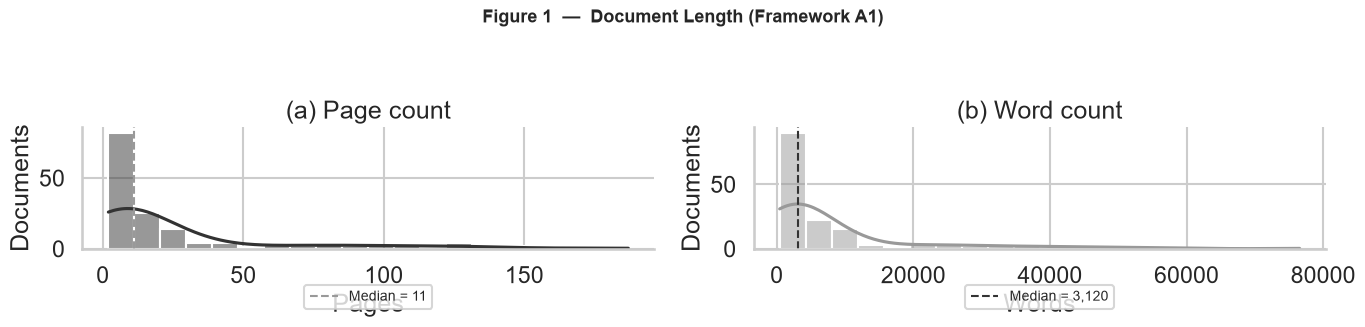

**Table 2a — Number of documents by 10-page increments**

,Page range,Documents (n)
0,0-9,74
1,10-19,30
2,20-29,17
3,30-39,6
4,40-49,2
5,50-59,2
6,60-69,3
7,70-79,1
8,80-89,5
9,90-99,1


**Policy briefs longer than two pages:** 133 of 154 (86.4%)

In [80]:
display(Markdown('**Table 1 — Extraction pipeline output sizes**'))
display(pd.DataFrame({
    'Output file': ['documents.csv', 'structural_core.csv', 'recommendations.csv', 'frames.csv'],
    'Rows': [len(documents), len(structural_core), len(recommendations), len(frames)],
    'Unique documents': [
        documents['doc_id'].nunique()       if len(documents)       else 0,
        structural_core['doc_id'].nunique() if len(structural_core) else 0,
        recommendations['doc_id'].nunique() if len(recommendations) else 0,
        frames['doc_id'].nunique()          if len(frames)          else 0,
    ],
}).set_index('Output file'))

_desc = (
    documents[['page_count', 'word_count']]
    .rename(columns={'page_count': 'Pages', 'word_count': 'Words'})
    .describe()
    .loc[['mean', '50%', 'std', 'min', 'max']]
    .rename(index={'50%': 'median'})
    .round(1)
)
display(Markdown('**Table 2 — Document length summary statistics**'))
display(_desc.T)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(analysis_df['A1_page_count'], bins=20, kde=True, ax=axes[0], color=C_PRIMARY)
axes[0].set_title('(a) Page count')
axes[0].set_xlabel('Pages')
axes[0].set_ylabel('Documents')
_med_p = analysis_df['A1_page_count'].median()
axes[0].axvline(_med_p, color=C_ACCENT, linestyle='--', linewidth=1.5, label=f'Median = {_med_p:.0f}')
axes[0].legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.24))

if _has_col(documents, 'word_count'):
    sns.histplot(documents['word_count'].dropna(), bins=20, kde=True, ax=axes[1], color=C_ACCENT)
    axes[1].set_title('(b) Word count')
    axes[1].set_xlabel('Words')
    axes[1].set_ylabel('Documents')
    _med_w = documents['word_count'].median()
    axes[1].axvline(_med_w, color=C_PRIMARY, linestyle='--', linewidth=1.5, label=f'Median = {_med_w:,.0f}')
    axes[1].legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.24))

fig.suptitle('Figure 1  —  Document Length (Framework A1)', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.2, 1, 0.94))
save_standalone(fig, 'fig1_document_length')
plt.show()
sns.set_context('talk')

_page_bins = (analysis_df['A1_page_count'].dropna().astype(int) // 10) * 10
if len(_page_bins):
    page_bin_table = (
        _page_bins.value_counts().sort_index()
        .rename_axis('Page-bin start')
        .rename('Documents (n)')
        .reset_index()
    )
    page_bin_table['Page range'] = page_bin_table['Page-bin start'].apply(
        lambda x: f'{x}-{x + 9}'
    )
    page_bin_table = page_bin_table[['Page range', 'Documents (n)']]
    display(Markdown('**Table 2a — Number of documents by 10-page increments**'))
    display(page_bin_table)

_over_two_pages = analysis_df['A1_page_count'].gt(2).sum()
_page_count_available = analysis_df['A1_page_count'].notna().sum()
display(Markdown(
    f'**Policy briefs longer than two pages:** {_over_two_pages} of {_page_count_available} '
    f'({_over_two_pages / _page_count_available:.1%})'
))

## 2. Validation and Cross-validation[](#2.-AI-Extraction-Quality:-Cross-Validation)

The analysis uses a **two-pass extraction design**. Pass 1 sends the full PDF text to the LLM, providing rich document-level context. Pass 2 re-runs the LLM over each isolated solution sentence identified in Pass 1, providing highly concentrated per-sentence context at the cost of losing broader document cues.

Extraction quality was assessed by comparing AI-extracted solution segments against **1,333 manually coded segments** across **106 documents**. Two agreement metrics are reported:

* **Presence agreement**: do AI and manual coders agree on whether a document contains solutions at all?
* **Content overlap — exact**: is the normalized text of a manual segment present as a substring in any AI extraction for the same document (or vice versa)?

Figure 2(a-i) shows the two validation metrics. Figure 2(a-ii) compares **field fill rates between Pass 1 (full-text) and Pass 2 (isolated snippet)** for four context-sensitive fields: actor type, target audience, expected outcomes, and instrument type. Fields whose extraction depends on information outside the solution sentence itself — such as actor type and instrument type — typically show lower fill rates in Pass 2.

Figure 2(b) summarises the AI–manual count agreement as a binned cross-table. Rows represent AI extraction counts per document; columns represent manual coding counts. Counts on the diagonal indicate agreement; off-diagonal counts indicate over- or under-extraction.

Figure 2(c) provides a full field-level comparison between Pass 1 and Pass 2, reporting fill rate and agreement rate for all shared fields, including `target_raw`, `expected_outcomes`, `implementation_steps`, and `trade_offs`.

AI solutions extracted:          1,041
Manually coded segments:         1,333
Documents with AI solutions:     152
Documents with manual solutions: 106


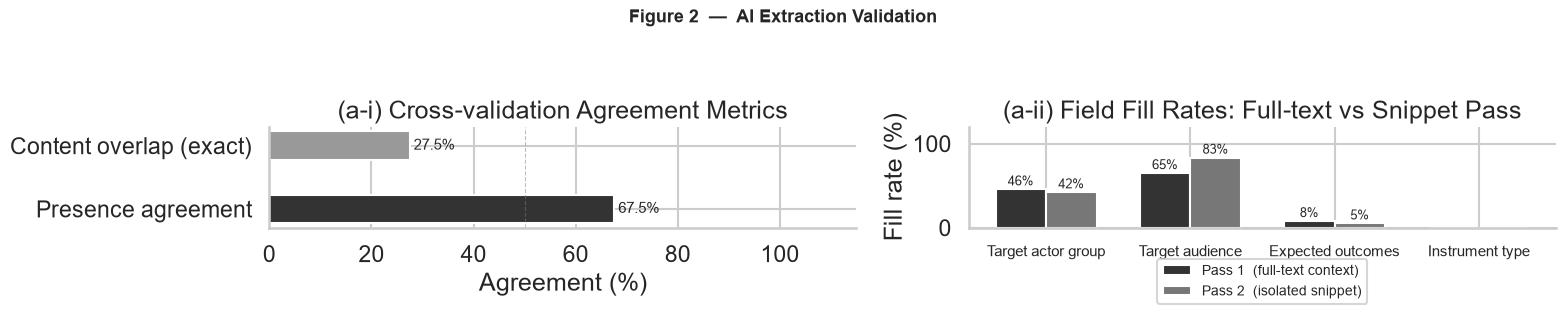

**Figure 2(b) — Binned solution-count cross-table (documents)**

Manual segments per doc →,0,1,2–3,4–6,7+
AI extractions per doc ↓,,,,,
0,0,0,0,0,2
1,3,1,2,0,0
2–3,8,3,4,2,4
4–6,20,1,5,20,8
7+,17,0,3,21,30


In [81]:
import json as _json

pov  = crossval_metrics.get('primary', {})
ov   = pov.get('overview', {})
pres = pov.get('presence_agreement', {})
typ  = pov.get('type_agreement', {})
ov_e = pov.get('overlap_exact', {})

# Load context comparison fill rates
_m_ctx = _json.loads((CROSSVAL_DIR / 'metrics.json').read_text()) if (CROSSVAL_DIR / 'metrics.json').exists() else {}
fill = _m_ctx.get('context_comparison', {}).get('fill_rates', {})

print(f"AI solutions extracted:          {ov.get('ai_total_solutions',  'n/a'):,}")
print(f"Manually coded segments:         {ov.get('manual_total_solutions', 'n/a'):,}")
print(f"Documents with AI solutions:     {ov.get('ai_solution_docs',    'n/a')}")
print(f"Documents with manual solutions: {ov.get('manual_solution_docs','n/a')}")

CONTEXT_KEY_FIELDS = {
    'actor_type':        'Target actor group',
    'target_raw':        'Target audience',
    'expected_outcomes': 'Expected outcomes',
    'instrument_type':   'Instrument type',
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ── (a-i) Cross-validation agreement metrics ──────────────────────────
metrics_data = {
    'Presence agreement':      pres.get('rate', 0),
    'Content overlap (exact)': ov_e.get('overlap_rate', 0),
}
bar_colors = [C_PRIMARY, C_ACCENT]
bars = axes[0].barh(
    list(metrics_data.keys()),
    [v * 100 for v in metrics_data.values()],
    color=bar_colors, edgecolor='white', height=0.45,
)
for bar, val in zip(bars, metrics_data.values()):
    axes[0].text(
        bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
        f'{val:.1%}', va='center', fontsize=11,
    )
axes[0].set_xlim(0, 115)
axes[0].axvline(50, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_xlabel('Agreement (%)')
axes[0].set_title('(a-i) Cross-validation Agreement Metrics')

# ── (a-ii) P1 vs P2 fill rates for key context-sensitive fields ───────
ctx_labels = list(CONTEXT_KEY_FIELDS.values())
p1_vals = [(fill.get(f) or {}).get('pass1') or 0.0 for f in CONTEXT_KEY_FIELDS]
p2_vals = [(fill.get(f) or {}).get('pass2') or 0.0 for f in CONTEXT_KEY_FIELDS]
x2 = np.arange(len(CONTEXT_KEY_FIELDS))
w2 = 0.35

b1 = axes[1].bar(x2 - w2/2, [v * 100 for v in p1_vals], w2,
                 label='Pass 1  (full-text context)', color=C_PRIMARY, edgecolor='white')
b2 = axes[1].bar(x2 + w2/2, [v * 100 for v in p2_vals], w2,
                 label='Pass 2  (isolated snippet)',   color=C_SECONDARY, edgecolor='white')
for bar in list(b1) + list(b2):
    h = bar.get_height()
    if h > 2:
        axes[1].text(bar.get_x() + bar.get_width() / 2, h + 1.5,
                     f'{h:.0f}%', ha='center', va='bottom', fontsize=9)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(ctx_labels, fontsize=11)
axes[1].set_ylim(0, 120)
axes[1].set_ylabel('Fill rate (%)')
axes[1].legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.24))
axes[1].set_title('(a-ii) Field Fill Rates: Full-text vs Snippet Pass')

fig.suptitle('Figure 2  —  AI Extraction Validation', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.2, 1, 0.94))
save_standalone(fig, 'fig2_extraction_validation')
plt.show()

# ── Figure 2(b): Binned solution-count cross-table ────────────────────
if len(comparison_df) and 'ai_count' in comparison_df.columns and 'manual_count' in comparison_df.columns:
    _bins = [0, 1, 2, 4, 7, float('inf')]
    _lbls = ['0', '1', '2–3', '4–6', '7+']
    _ai_b  = pd.cut(comparison_df['ai_count'],     bins=_bins, labels=_lbls, right=False)
    _man_b = pd.cut(comparison_df['manual_count'], bins=_bins, labels=_lbls, right=False)
    _ct = pd.crosstab(_ai_b, _man_b)
    _ct.index.name   = 'AI extractions per doc  ↓'
    _ct.columns.name = 'Manual segments per doc  →'
    display(Markdown('**Figure 2(b) — Binned solution-count cross-table (documents)**'))
    display(_ct.style.background_gradient(cmap=GREY_CMAP).format('{:,}'))

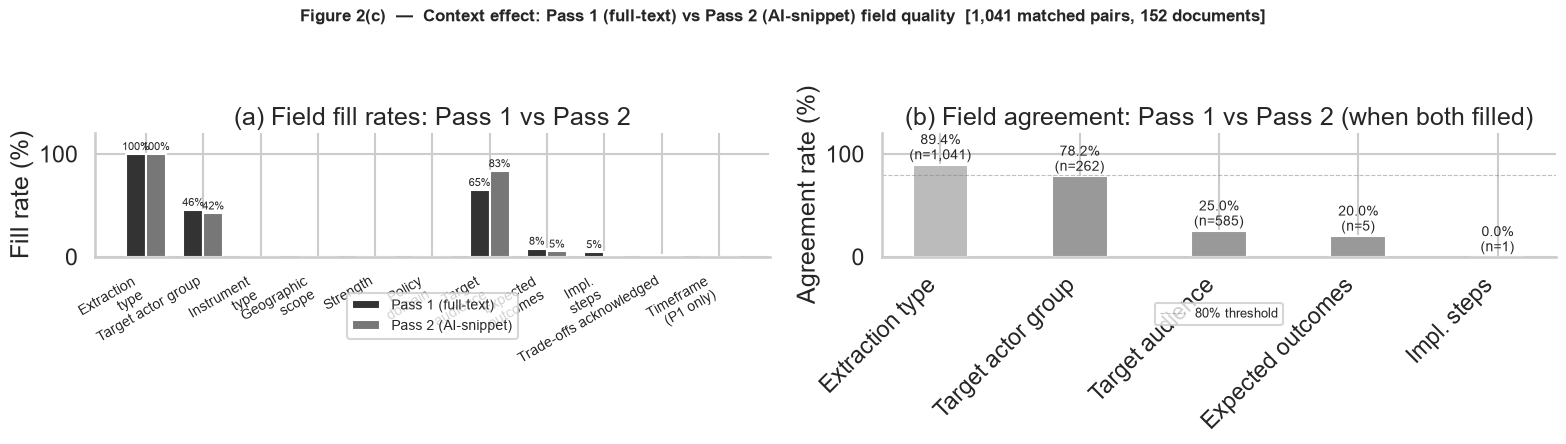

Key findings:
  actor_type: Pass 1 fill 45.7%  |  Pass 2 fill 42.3%
  target_raw: Pass 1 fill 65.0%  |  Pass 2 fill 83.4%
  extraction_type: Pass 1 fill 100.0%  |  Pass 2 fill 100.0%
  extraction_type agreement: 89.4%  (931/1041 pairs)
  Median confidence delta (Pass 2 - Pass 1): +0.00


In [82]:
import json as _json

# Reload metrics to pick up context_comparison section
_m = _json.loads((CROSSVAL_DIR / 'metrics.json').read_text())
cc   = _m.get('context_comparison', {})
fill = cc.get('fill_rates', {})
agr  = cc.get('agreement_rates', {})

FIELD_LABELS = {
    'extraction_type':      'Extraction\ntype',
    'actor_type':           'Target actor group',
    'instrument_type':      'Instrument\ntype',
    'geographic_scope':     'Geographic\nscope',
    'strength':             'Strength',
    'policy_domain':        'Policy\ndomain',
    'target_raw':           'Target\naudience',
    'expected_outcomes':    'Expected\noutcomes',
    'implementation_steps': 'Impl.\nsteps',
    'trade_offs':           'Trade-offs acknowledged',
    'timeframe':            'Timeframe\n(P1 only)',
}

fields   = list(FIELD_LABELS.keys())
p1_rates = [(fill.get(f) or {}).get('pass1') or 0.0 for f in fields]
p2_rates = [(fill.get(f) or {}).get('pass2') or 0.0 for f in fields]

x = np.arange(len(fields))
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# (a) Fill rates grouped bar
bars1 = axes[0].bar(x - w/2, [r * 100 for r in p1_rates], w,
                    label='Pass 1 (full-text)', color=C_PRIMARY, edgecolor='white')
bars2 = axes[0].bar(x + w/2, [r * 100 for r in p2_rates], w,
                    label='Pass 2 (AI-snippet)', color=C_SECONDARY, edgecolor='white')
for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    if h > 2:
        axes[0].text(bar.get_x() + bar.get_width() / 2, h + 1.5,
                     f'{h:.0f}%', ha='center', va='bottom', fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels([FIELD_LABELS[f] for f in fields], rotation=30, ha='right', fontsize=10)
axes[0].set_ylabel('Fill rate (%)')
axes[0].set_ylim(0, 120)
axes[0].legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.24))
axes[0].set_title('(a) Field fill rates: Pass 1 vs Pass 2')

# (b) Agreement rates (only fields with sufficient pairs)
agr_fields = [(f, FIELD_LABELS[f]) for f in FIELD_LABELS
              if agr.get(f, {}).get('total', 0) > 0]
agr_labels = [lbl.replace('\n', ' ') for _, lbl in agr_fields]
agr_rates  = [agr[f]['rate'] * 100 for f, _ in agr_fields]
agr_totals = [agr[f]['total'] for f, _ in agr_fields]
colors_agr = [C_AGREE if r >= 80 else C_ACCENT for r in agr_rates]

agr_bars = axes[1].bar(agr_labels, agr_rates, color=colors_agr, edgecolor='white', width=0.4)
for tick_label in axes[1].get_xticklabels():
    tick_label.set_rotation(45)
    tick_label.set_ha('right')
for bar, r, n in zip(agr_bars, agr_rates, agr_totals):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                 f'{r:.1f}%\n(n={n:,})', ha='center', va='bottom', fontsize=10)
axes[1].axhline(80, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, label='80% threshold')
axes[1].set_ylim(0, 120)
axes[1].set_ylabel('Agreement rate (%)')
axes[1].set_title('(b) Field agreement: Pass 1 vs Pass 2 (when both filled)')
axes[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.32))

fig.suptitle(
    f'Figure 2(c)  \u2014  Context effect: Pass 1 (full-text) vs Pass 2 (AI-snippet) field quality'
    f'  [{cc.get("matched_pairs", "n/a"):,} matched pairs, {cc.get("documents", "n/a")} documents]',
    fontsize=12, fontweight='bold',
)
plt.tight_layout(rect=(0, 0.3, 1, 0.94))
save_standalone(fig, 'fig2c_context_effect')
plt.show()

print("Key findings:")
for f, lbl in [('actor_type', 'actor_type'), ('target_raw', 'target_raw'), ('extraction_type', 'extraction_type')]:
    fr = fill.get(f, {})
    p1v = fr.get('pass1')
    p2v = fr.get('pass2')
    p1s = f'{p1v:.1%}' if p1v is not None else 'n/a'
    p2s = f'{p2v:.1%}' if p2v is not None else 'n/a'
    print(f'  {lbl}: Pass 1 fill {p1s}  |  Pass 2 fill {p2s}')
if agr.get('extraction_type', {}).get('rate') is not None:
    a = agr['extraction_type']
    print(f"  extraction_type agreement: {a['rate']:.1%}  ({a['agreed']}/{a['total']} pairs)")
if cc.get('confidence_delta_median') is not None:
    print(f"  Median confidence delta (Pass 2 - Pass 1): {cc['confidence_delta_median']:+.2f}")

### Extraction-count reconciliation and coverage gaps

The AI solution count reported above (Figure 2) comes from the Pass-2 snippet reprocessing (`recommendations_snippet_ai.csv`), which differs slightly from the Pass-1 full-text extraction (`recommendations.csv`) because it reprocesses each Pass-1 item individually and can occasionally split or drop items. The cell below reconciles the two counts and flags any document dropped between passes. It is followed by a list of documents where AI and human coders disagree on whether the brief contains any solutions at all.

In [83]:
pass1_total = len(recommendations) if len(recommendations) else 0
pass1_solutions = int(recommendations['extraction_type'].isin(RECOMMENDATION_ANALYSIS_TYPES).sum()) if len(recommendations) else 0

snippet_ai_path = OUTPUT_DIR / 'recommendations_snippet_ai.csv'
snippet_ai = pd.read_csv(snippet_ai_path) if snippet_ai_path.exists() else pd.DataFrame()
pass2_solutions = len(snippet_ai)

reported_ai_total = ov.get('ai_total_solutions') if 'ov' in dir() else crossval_metrics.get('primary', {}).get('overview', {}).get('ai_total_solutions')

print(f"Pass 1 (full-text) — all extraction types:            {pass1_total:,} rows, {recommendations['doc_id'].nunique() if len(recommendations) else 0} documents")
print(f"Pass 1 (full-text) — recommendation/policy_option only: {pass1_solutions:,} rows")
print(f"Pass 2 (snippet reprocessing) — solutions:              {pass2_solutions:,} rows, {snippet_ai['doc_id'].nunique() if len(snippet_ai) else 0} documents")
print(f"Reported in crossval/metrics.json (ai_total_solutions): {reported_ai_total}")

if len(recommendations) and len(snippet_ai):
    docs_pass1 = set(recommendations['doc_id'].unique())
    docs_pass2 = set(snippet_ai['doc_id'].unique())
    dropped = sorted(docs_pass1 - docs_pass2)
    added   = sorted(docs_pass2 - docs_pass1)
    if dropped:
        print(f"\nDocuments with Pass-1 items but absent from the Pass-2 snippet file ({len(dropped)}): {dropped}")
    if added:
        print(f"Documents present in Pass-2 but not Pass-1 ({len(added)}): {added}")
    if not dropped and not added:
        print("\nNo documents were dropped or added between Pass 1 and Pass 2 — the count difference is due to per-item splitting/merging during snippet reprocessing, not missing documents.")

Pass 1 (full-text) — all extraction types:            2,826 rows, 154 documents
Pass 1 (full-text) — recommendation/policy_option only: 2,673 rows
Pass 2 (snippet reprocessing) — solutions:              2,504 rows, 153 documents
Reported in crossval/metrics.json (ai_total_solutions): 1041

Documents with Pass-1 items but absent from the Pass-2 snippet file (1): ['resalliance_2']


In [84]:
if len(comparison_df) and {'ai_has_solutions', 'manual_has_solutions'}.issubset(comparison_df.columns):
    ai_only = comparison_df[comparison_df['ai_has_solutions'] & ~comparison_df['manual_has_solutions']]
    manual_only = comparison_df[comparison_df['manual_has_solutions'] & ~comparison_df['ai_has_solutions']]

    display(Markdown(
        f'**Documents where AI found solutions but the human coder found none** '
        f'({len(ai_only)} total, showing up to 10):'
    ))
    display(ai_only[['doc_id', 'ai_count', 'manual_count']].head(10).set_index('doc_id'))

    display(Markdown(
        f'**Documents where the human coder found solutions but AI found none** '
        f'({len(manual_only)} total, showing up to 10):'
    ))
    display(manual_only[['doc_id', 'ai_count', 'manual_count']].head(10).set_index('doc_id'))
else:
    print('warning: comparison.csv missing ai_has_solutions/manual_has_solutions columns; skipping mismatch tables.')

**Documents where AI found solutions but the human coder found none** (48 total, showing up to 10):

,ai_count,manual_count
doc_id,,
b4est_2,4,0
biomonitor_2,3,0
biomonitor_3,5,0
biomonitor_4,2,0
biomonitor_6,1,0
biomonitor_7,2,0
biores,8,0
coupled_2,3,0
effect_1,3,0


**Documents where the human coder found solutions but AI found none** (2 total, showing up to 10):

,ai_count,manual_count
doc_id,,
branches_1,0,17
branches_2,0,67


### C-D. Action orientation and facilitating role[](#4.-Action-Orientation-(Frameworks-C-&-D))

The **bridging role** (C) assesses whether a brief specifies *how* to act (C5 procedural clarity), *who* should act (C6 responsibility), and what outcomes are anticipated (C7). The **facilitating role** (D) extends this by asking whether the brief discusses broader impacts (D8) and trade-offs between options (D9).

Together these five dimensions measure the brief's *action-orientation* — its capacity to guide policy actors toward concrete decisions. Figure 4 shows percentages using indicator-specific denominators (recommendation documents for the first three indicators; policy-option documents for the last two). For example, a value of 79% means: "79% of documents with AI-extracted policy recommendations identify responsible actors for those recommendations."

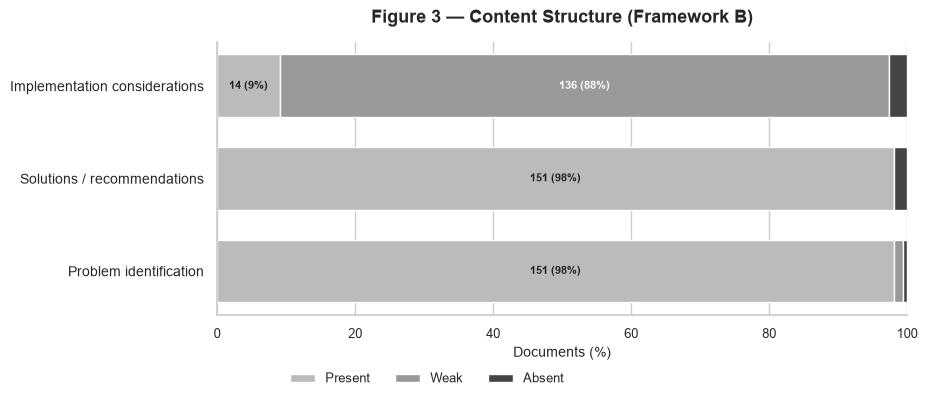

,Present (n),Present (%),Weak (n),Weak (%),Absent (n),Absent (%)
Dimension,,,,,,
Problem identification,151,98%,2,1%,1,1%
Solutions (policy recommendations or policy options),151,98%,0,0%,3,2%
Implementation considerations,14,9%,136,88%,4,3%


In [85]:
STATUS_COLORS = {
    'present': C_AGREE,
    'weak':    C_ACCENT,
    'absent':  C_DISAGREE,
}

dims_b = [
    ('B2_problem_identified',    'Problem identification'),
    ('B3_solutions_status',      'Solutions (policy recommendations or policy options)'),
    ('B4_implementation_status', 'Implementation considerations'),
]

N = len(analysis_df)
available_b = [(c, t) for c, t in dims_b if c in analysis_df.columns]
dim_labels  = [t for _, t in available_b]
levels      = ['present', 'weak', 'absent']

sns.set_context('notebook')
fig, ax = plt.subplots(figsize=(10, 4.4))
left = np.zeros(len(available_b), dtype=float)

for level in levels:
    counts = np.array([
        int((analysis_df[col].astype(str).str.lower() == level).sum())
        for col, _ in available_b
    ])
    pct = (counts / N) * 100 if N else np.zeros_like(counts, dtype=float)
    bars = ax.barh(dim_labels, pct, left=left,
                   color=STATUS_COLORS[level], edgecolor='white',
                   label=level.capitalize(), height=0.68)
    for bar, cnt in zip(bars, counts):
        if cnt > 2 and bar.get_width() >= 8:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f'{cnt} ({cnt / N:.0%})',
                ha='center', va='center', fontsize=8,
                color='#222222' if level == 'present' else 'white',
                fontweight='bold',
            )
    left = left + pct

ax.set_xlim(0, 100)
ax.set_yticks(np.arange(len(dim_labels)))
ax.set_yticklabels([
    'Problem identification',
    'Solutions / recommendations',
    'Implementation considerations',
], fontsize=10)
ax.set_xlabel('Documents (%)', fontsize=10)
ax.tick_params(axis='x', labelsize=9)
ax.set_title('Figure 3 — Content Structure (Framework B)', fontsize=13, fontweight='bold', pad=14)
legend_handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(legend_handles, legend_labels, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, 0.035), frameon=False, fontsize=9)
fig.subplots_adjust(left=0.29, right=0.98, top=0.84, bottom=0.22)
save_standalone(fig, 'fig3_content_structure_ai')
plt.show()
sns.set_context('talk')

# Summary table
rows_b = []
for col, label in available_b:
    s = analysis_df[col].astype(str).str.lower()
    rows_b.append({
        'Dimension':     label,
        'Present (n)':   int((s == 'present').sum()),
        'Present (%)':   f'{(s == "present").mean():.0%}',
        'Weak (n)':      int((s == 'weak').sum()),
        'Weak (%)':      f'{(s == "weak").mean():.0%}',
        'Absent (n)':    int((s == 'absent').sum()),
        'Absent (%)':    f'{(s == "absent").mean():.0%}',
    })
if rows_b:
    display(pd.DataFrame(rows_b).set_index('Dimension'))

### B (continued). Human-coded core components vs. AI

`data/Policy Briefs corpus.csv.xlsx` (sheet "Final Policy Brief List") includes human-coded presence flags for all three core components — **"Problem component present"**, **"Solutions component present"**, and **"Implementation considerations component present"** (each Yes/No) — matched to documents via `doc_id`. Figure 3b compares these against the AI-derived B2/B3/B4 indicators, to help identify where AI labelling of core components diverges from human coding.

Matched 154 of 154 documents to the human-coded corpus sheet; unmatched are treated as absent for percentage calculations.


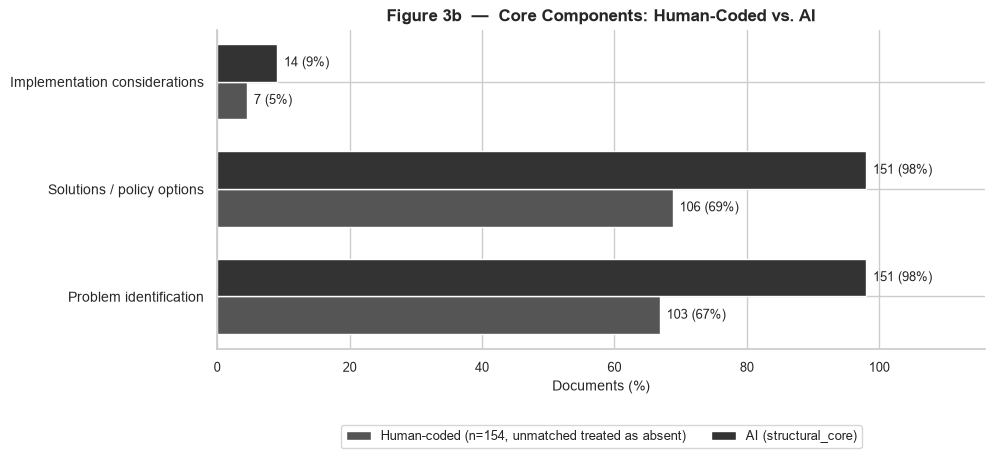

,Human-coded (n),Human-coded (%),AI (n),AI (%)
Dimension,,,,
Problem identification,103,66.883117,151,98.051948
Solutions (policy recommendations or policy options),106,68.831169,151,98.051948
Implementation considerations,7,4.545455,14,9.090909


In [86]:
CORPUS_XLSX_PATH = Path.cwd() / 'data' / 'Policy Briefs corpus.csv.xlsx'
CORPUS_SHEET_NAME = 'Final Policy Brief List '

def _load_corpus_sheet():
    if not CORPUS_XLSX_PATH.exists():
        print(f'warning: {CORPUS_XLSX_PATH} not found; skipping human-coded comparisons.')
        return pd.DataFrame()
    corpus = pd.read_excel(CORPUS_XLSX_PATH, sheet_name=CORPUS_SHEET_NAME)
    corpus['doc_id'] = corpus['Related File Pdf Title'].apply(
        lambda x: create_document_id(Path(str(x))) if pd.notna(x) else None
    )
    corpus = corpus.dropna(subset=['doc_id'])
    # A handful of titles map to the same doc_id (e.g. re-listed briefs); keep the first entry.
    return corpus.drop_duplicates(subset='doc_id', keep='first')

def _parse_yes_no_or_x(value):
    if pd.isna(value):
        return False
    return str(value).strip().lower() in ('yes', 'y', 'true', 'x', '1')

import sys
sys.path.insert(0, str(Path.cwd() / 'src'))
from policybrief.utils import create_document_id

corpus_sheet = _load_corpus_sheet()

CORE_COMPONENTS = [
    ('Problem identification', 'Problem component present', 'B2_problem_identified'),
    ('Solutions (policy recommendations or policy options)', 'Solutions component present', 'B3_solutions_status'),
    ('Implementation considerations', 'Implementation considerations component present', 'B4_implementation_status'),
]

if len(corpus_sheet):
    available_core = [
        (label, corpus_col, ai_col) for label, corpus_col, ai_col in CORE_COMPONENTS
        if corpus_col in corpus_sheet.columns and ai_col in analysis_df.columns
    ]
    corpus_by_doc = corpus_sheet.set_index('doc_id')
    matched = analysis_df['doc_id'].isin(corpus_by_doc.index)
    print(f'Matched {matched.sum()} of {len(analysis_df)} documents to the human-coded corpus sheet; unmatched are treated as absent for percentage calculations.')

    plot_rows = []
    for label, corpus_col, ai_col in available_core:
        human_present = analysis_df['doc_id'].map(corpus_by_doc[corpus_col]).apply(_parse_yes_no_or_x)
        ai_present = (analysis_df[ai_col].astype(str).str.lower() == 'present')
        plot_rows.append({
            'label': label,
            'human_n': int(human_present.sum()),
            'human_pct': float(human_present.mean()) * 100,
            'ai_n': int(ai_present.sum()),
            'ai_pct': float(ai_present.mean()) * 100,
        })

    df_core = pd.DataFrame(plot_rows)
    if not df_core.empty:
        sns.set_context('notebook')
        y = np.arange(len(df_core))
        h = 0.35
        fig, ax = plt.subplots(figsize=(12, 5.5))
        human_bars = ax.barh(y - h/2, df_core['human_pct'], height=h, color=C_WARM, edgecolor='white',
                             label=f'Human-coded (n={len(analysis_df)}, unmatched treated as absent)')
        ai_bars = ax.barh(y + h/2, df_core['ai_pct'], height=h, color=C_PRIMARY, edgecolor='white',
                          label='AI (structural_core)')
        for bar, n, v in zip(human_bars, df_core['human_n'], df_core['human_pct']):
            ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f'{n} ({v:.0f}%)', va='center', fontsize=9)
        for bar, n, v in zip(ai_bars, df_core['ai_n'], df_core['ai_pct']):
            ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f'{n} ({v:.0f}%)', va='center', fontsize=9)

        ax.set_yticks(y)
        ax.set_yticklabels([
            'Problem identification', 'Solutions / policy options',
            'Implementation considerations',
        ], fontsize=10)
        ax.set_xlim(0, 116)
        ax.set_xlabel('Documents (%)', fontsize=10)
        ax.tick_params(axis='x', labelsize=9)
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), fontsize=9, ncol=2)
        ax.set_title('Figure 3b  —  Core Components: Human-Coded vs. AI', fontsize=12, fontweight='bold')
        fig.subplots_adjust(left=0.34, right=0.98, top=0.82, bottom=0.24)
        save_standalone(fig, 'fig3b_core_components_human_vs_ai')
        plt.show()
        sns.set_context('talk')

        display(
            df_core.rename(columns={'label': 'Dimension', 'human_n': 'Human-coded (n)', 'human_pct': 'Human-coded (%)', 'ai_n': 'AI (n)', 'ai_pct': 'AI (%)'})
            .set_index('Dimension')
        )
    else:
        print('Human-coded core-component comparison skipped (no matching columns available).')
else:
    print('Human-coded core-component comparison skipped (corpus sheet unavailable).')

### C-D. Action orientation and facilitating role[](#4.-Action-Orientation-(Frameworks-C-&-D))

The **bridging role** (C) assesses whether a brief specifies *how* to act (C5 procedural clarity), *who* should act (C6 responsibility), and what outcomes are anticipated (C7). The **facilitating role** (D) extends this by asking whether the brief discusses broader impacts (D8) and trade-offs between options (D9).

Together these five dimensions measure the brief's *action-orientation* — its capacity to guide policy actors toward concrete decisions. Figure 4 shows percentages using indicator-specific denominators (recommendation documents for the first three indicators; policy-option documents for the last two). For example, a value of 79% means: "79% of documents with AI-extracted policy recommendations identify responsible actors for those recommendations."

In [87]:
MANUAL_SNIPPET_CANDIDATES = [
    OUTPUT_DIR / 'recommendations_snippet_manual.csv',
    CROSSVAL_DIR / 'recommendations_snippet_manual.csv',
]
AI_FULL_TEXT_CANDIDATES = [
    OUTPUT_DIR / 'recommendations.csv',
]
MANUAL_REPORT_LABEL = 'Human-identified solution passages (LLM-assisted field extraction)'
AI_REPORT_LABEL = 'LLM-identified solution passages (complete-brief extraction)'

def _load_first_existing(paths):
    for path in paths:
        if path.exists():
            return pd.read_csv(path), path
    return pd.DataFrame(), None

manual_recs, manual_recs_path = _load_first_existing(MANUAL_SNIPPET_CANDIDATES)
ai_recs, ai_recs_path = _load_first_existing(AI_FULL_TEXT_CANDIDATES)

if len(manual_recs):
    if 'actor_raw' not in manual_recs.columns and 'actor_text_raw' in manual_recs.columns:
        manual_recs['actor_raw'] = manual_recs['actor_text_raw']
    if 'target_raw' not in manual_recs.columns and 'target_text_raw' in manual_recs.columns:
        manual_recs['target_raw'] = manual_recs['target_text_raw']

report_sources = []
if len(manual_recs):
    manual_recs = manual_recs.copy()
    manual_recs['provenance'] = manual_recs.get(
        'source_provenance', 'manually_coded_recommendation_segment'
    )
    report_sources.append(manual_recs)
else:
    print('warning: manually coded recommendation-segment output not found; downstream comparisons will skip that provenance')

if len(ai_recs):
    ai_recs = ai_recs.copy()
    ai_recs['provenance'] = ai_recs.get('source_provenance', 'full_policy_brief_text')
    report_sources.append(ai_recs)

report_recommendations = pd.concat(report_sources, ignore_index=True, sort=False) if report_sources else pd.DataFrame()

if len(report_recommendations):
    provenance_labels = {
        'manually_coded_recommendation_segment': MANUAL_REPORT_LABEL,
        'full_policy_brief_text': AI_REPORT_LABEL,
    }
    provenance_tag = report_recommendations['provenance'].map(provenance_labels).fillna(
        report_recommendations['provenance']
    )
    report_recommendations['actor_source_label'] = provenance_tag
    report_recommendations['target_source_label'] = provenance_tag
    display(Markdown('**Downstream provenance sources**'))
    display(pd.DataFrame({
        'Source': [MANUAL_REPORT_LABEL, AI_REPORT_LABEL],
        'Available rows': [len(manual_recs), len(ai_recs)],
        'File': [str(manual_recs_path) if manual_recs_path else 'missing', str(ai_recs_path) if ai_recs_path else 'missing'],
    }))
else:
    print('warning: no downstream recommendation sources available for source-aware reporting')

if len(report_recommendations):
    derived_dir = OUTPUT_DIR / 'reporting'
    derived_dir.mkdir(parents=True, exist_ok=True)
    if len(manual_recs):
        manual_recs.to_csv(derived_dir / 'recommendations_manual_segment_llm_reporting.csv', index=False)
    if len(ai_recs):
        ai_recs.to_csv(derived_dir / 'recommendations_ai_full_text_reporting.csv', index=False)
    report_recommendations.to_csv(derived_dir / 'recommendations_combined_by_provenance.csv', index=False)
    print(f'Prepared source-aware reporting tables in {derived_dir}')

**Downstream provenance sources**

,Source,Available rows,File
0,Human-identified solution passages (LLM-assist...,2074,c:\Users\DaSchulz\OneDrive - European Forest I...
1,LLM-identified solution passages (complete-bri...,2826,c:\Users\DaSchulz\OneDrive - European Forest I...


Prepared source-aware reporting tables in c:\Users\DaSchulz\OneDrive - European Forest Institute\Dokumente\research\PolicyBriefAnalysis\output\reporting


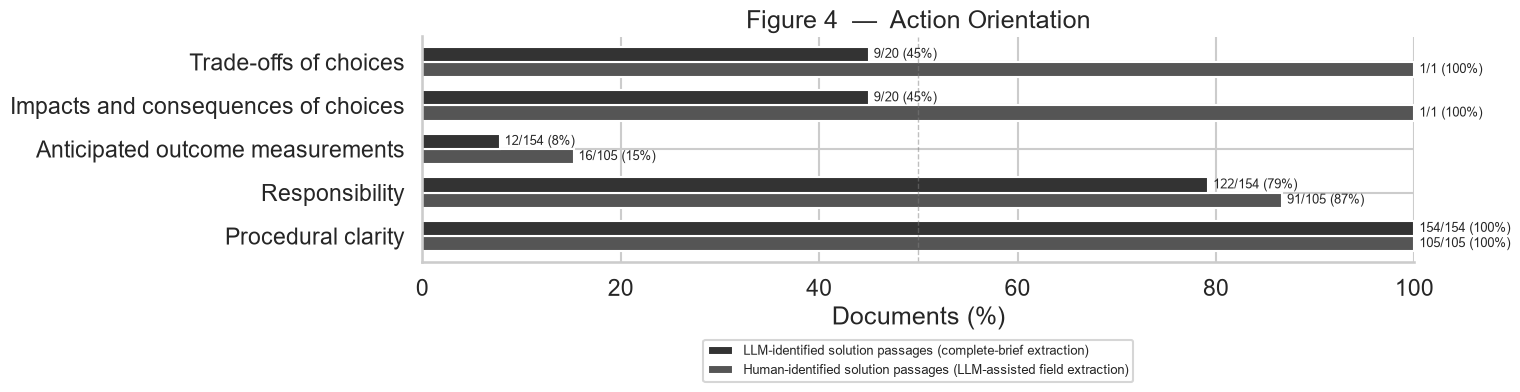

,Human-identified solution passages (LLM-assisted field extraction) numerator,Human-identified solution passages (LLM-assisted field extraction) denominator,Human-identified solution passages (LLM-assisted field extraction) (%),LLM-identified solution passages (complete-brief extraction) numerator,LLM-identified solution passages (complete-brief extraction) denominator,LLM-identified solution passages (complete-brief extraction) (%)
Dimension,,,,,,
Procedural clarity,105,105,100.000000,154,154,100.000000
Responsibility,91,105,86.666667,122,154,79.220779
Anticipated outcome measurements,16,105,15.238095,12,154,7.792208
Impacts and consequences of choices,1,1,100.000000,9,20,45.000000
Trade-offs of choices,1,1,100.000000,9,20,45.000000


In [88]:
indicators_cd = [
    ('Procedural clarity', 'C5_procedural_clarity', 'recommendation'),
    ('Responsibility', 'C6_responsibility', 'recommendation'),
    ('Anticipated outcome measurements', 'C7_anticipated_outcomes', 'recommendation'),
    ('Impacts and consequences of choices', 'D8_impacts_proxy', 'policy_option'),
    ('Trade-offs of choices', 'D9_tradeoffs', 'policy_option'),
]

if len(report_recommendations):
    fig, ax = plt.subplots(figsize=(16, 5))
    plot_rows = []

    actor_col = 'actor_raw' if 'actor_raw' in report_recommendations.columns else None
    ext_col = 'extraction_type' if 'extraction_type' in report_recommendations.columns else None
    impl_col = 'implementation_steps' if 'implementation_steps' in report_recommendations.columns else None
    manual_provenance = 'manually_coded_recommendation_segment'
    has_manual = report_recommendations['provenance'].eq(manual_provenance).any()

    for label, _, denominator_type in indicators_cd:
        if ext_col is None:
            continue

        rows = report_recommendations.copy()
        rows[ext_col] = rows[ext_col].astype(str).str.lower()
        if denominator_type == 'recommendation':
            denominator_mask = rows[ext_col].eq('recommendation')
        else:
            denominator_mask = rows[ext_col].eq('policy_option')

        if label == 'Procedural clarity':
            has_impl_text = rows[impl_col].astype(str).str.strip().ne('') if impl_col is not None else pd.Series(False, index=rows.index)
            numerator_mask = rows[ext_col].eq('implementation_step') | has_impl_text
        elif label == 'Responsibility':
            actor_non_null = rows[actor_col].fillna('').astype(str).str.strip().ne('') if actor_col is not None else pd.Series(False, index=rows.index)
            numerator_mask = rows[ext_col].eq('recommendation') & actor_non_null
        elif label == 'Anticipated outcome measurements':
            numerator_mask = rows[ext_col].eq('expected_outcome')
        elif label == 'Impacts and consequences of choices':
            numerator_mask = rows[ext_col].eq('expected_outcome')
        else:
            numerator_mask = rows[ext_col].eq('trade_off')

        source_rows = {}
        for prov_key, prov_label in [
            (manual_provenance, MANUAL_REPORT_LABEL),
            ('full_policy_brief_text', AI_REPORT_LABEL),
        ]:
            src_mask = rows['provenance'].eq(prov_key)
            if prov_key == manual_provenance and label in {
                'Impacts and consequences of choices', 'Trade-offs of choices'
            }:
                option_mask = rows['parent_id'].astype(str).str.lower().str.endswith('_option')
                denom_docs = set(rows.loc[src_mask & option_mask, 'doc_id'].dropna())
                numer_docs = set(rows.loc[src_mask & option_mask & numerator_mask, 'doc_id'].dropna())
            else:
                denom_docs = set(rows.loc[src_mask & denominator_mask, 'doc_id'].dropna())
                numer_docs = set(rows.loc[src_mask & numerator_mask, 'doc_id'].dropna())
            denom_n = len(denom_docs)
            numer_n = len(denom_docs & numer_docs)
            pct = (numer_n / denom_n * 100.0) if denom_n else np.nan
            source_rows[prov_label] = (numer_n, denom_n, pct)

        plot_rows.append({
            'label': label,
            'manual_n': source_rows[MANUAL_REPORT_LABEL][0],
            'manual_denom': source_rows[MANUAL_REPORT_LABEL][1],
            'manual_pct': source_rows[MANUAL_REPORT_LABEL][2],
            'ai_n': source_rows[AI_REPORT_LABEL][0],
            'ai_denom': source_rows[AI_REPORT_LABEL][1],
            'ai_pct': source_rows[AI_REPORT_LABEL][2],
        })

    df_cd = pd.DataFrame(plot_rows)
    if not df_cd.empty:
        y = np.arange(len(df_cd))
        h = 0.35

        manual_vals = df_cd['manual_pct'].fillna(0)
        manual_bars = ax.barh(y - h/2, manual_vals, height=h, color=C_WARM, edgecolor='white', label=MANUAL_REPORT_LABEL)
        ai_bars = ax.barh(y + h/2, df_cd['ai_pct'], height=h, color=C_PRIMARY, edgecolor='white', label=AI_REPORT_LABEL)

        for bar, val, num, den in zip(ai_bars, df_cd['ai_pct'], df_cd['ai_n'], df_cd['ai_denom']):
            if pd.notna(val):
                ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f'{num}/{den} ({val:.0f}%)', va='center', fontsize=9)

        for bar, val, num, den in zip(manual_bars, df_cd['manual_pct'], df_cd['manual_n'], df_cd['manual_denom']):
            if pd.notna(val):
                ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f'{num}/{den} ({val:.0f}%)', va='center', fontsize=9)
            else:
                ax.text(0.5, bar.get_y() + bar.get_height() / 2, 'n/a', va='center', fontsize=8, color='gray')

        ax.set_yticks(y)
        ax.set_yticklabels(df_cd['label'])
        ax.set_xlim(0, 100)
        ax.set_xlabel('Documents (%)')
        ax.axvline(50, color='gray', linestyle='--', linewidth=1, alpha=0.5)
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc='upper center', bbox_to_anchor=(0.5, -0.32), fontsize=9)
        ax.set_title('Figure 4  —  Action Orientation')
        fig.subplots_adjust(left=0.36, right=0.98, top=0.85, bottom=0.4)
        save_standalone(fig, 'fig4_action_orientation')
        plt.show()

        display(
            df_cd[['label', 'manual_n', 'manual_denom', 'manual_pct', 'ai_n', 'ai_denom', 'ai_pct']]
            .rename(columns={
                'label': 'Dimension',
                'manual_n': f'{MANUAL_REPORT_LABEL} numerator',
                'manual_denom': f'{MANUAL_REPORT_LABEL} denominator',
                'manual_pct': f'{MANUAL_REPORT_LABEL} (%)',
                'ai_n': f'{AI_REPORT_LABEL} numerator',
                'ai_denom': f'{AI_REPORT_LABEL} denominator',
                'ai_pct': f'{AI_REPORT_LABEL} (%)',
            })
            .set_index('Dimension')
        )
else:
    print('Source-aware Figure 4 skipped because no downstream recommendation sources were available.')

### E. Accessibility and readability[](#5.-Accessibility-(Framework-E))

Dimensions E11–E14 measure language complexity indicators that affect how easily a non-specialist policy audience can engage with a brief. Passive-voice share estimates the proportion of sentences using passive constructions; average sentence length and lexical diversity describe structural text complexity; Flesch Reading Ease and Flesch-Kincaid Grade Level provide standardized readability benchmarks (higher Flesch = easier; higher FK grade = harder).

Table 3 summarizes the key statistics; Figure 5 shows the full distribution of each indicator across the corpus.

**Table 3 — Accessibility indicator summary statistics (Framework E)**

,mean,median,std,min,max
Passive voice share,0.24,0.24,0.10,0.00,0.50
Avg sentence length (words),22.65,22.52,4.77,12.23,45.78
Lexical diversity,0.36,0.37,0.12,0.10,0.63
Flesch reading ease,20.59,20.24,8.89,-14.51,44.38
Flesch-Kincaid grade level,15.68,15.73,1.84,10.96,24.67


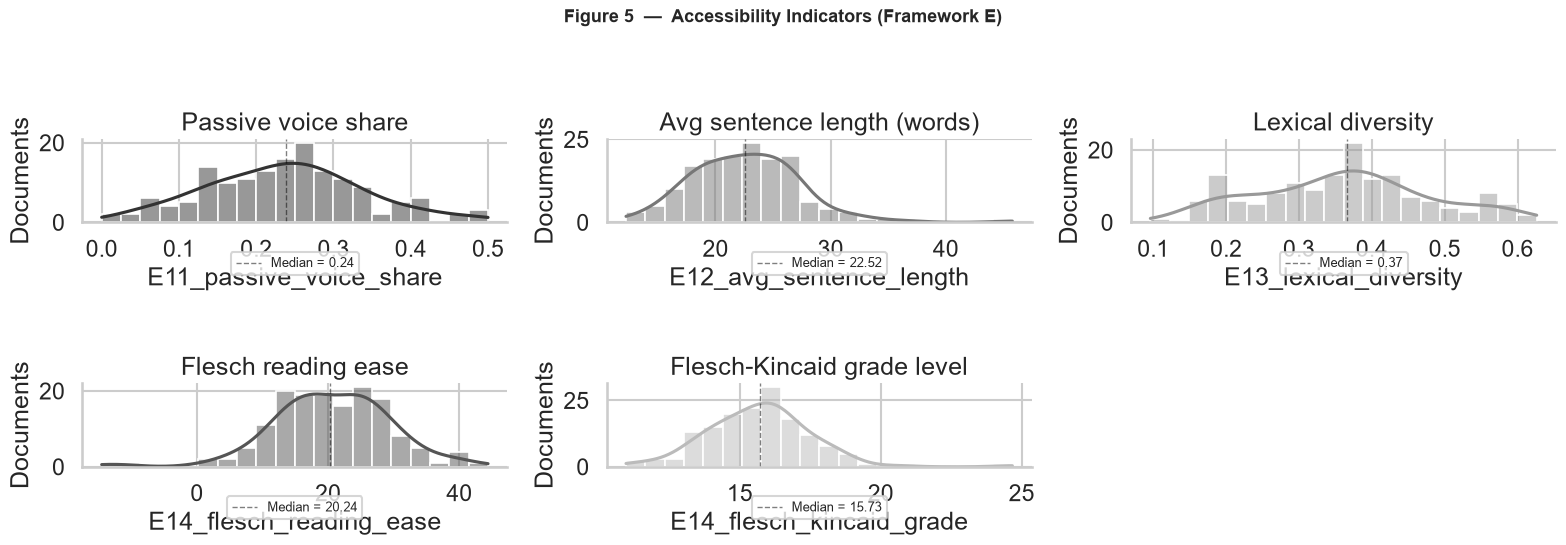

In [89]:
access_items = [
    ('Passive voice share',           'E11_passive_voice_share'),
    ('Avg sentence length (words)', 'E12_avg_sentence_length'),
    ('Lexical diversity',           'E13_lexical_diversity'),
    ('Flesch reading ease',         'E14_flesch_reading_ease'),
    ('Flesch-Kincaid grade level',  'E14_flesch_kincaid_grade'),
]
avail_a = [(l, c) for l, c in access_items if c in analysis_df.columns and analysis_df[c].notna().any()]

if avail_a:
    stats_a = pd.DataFrame({
        l: analysis_df[c].describe()[['mean', '50%', 'std', 'min', 'max']]
        for l, c in avail_a
    }).T.rename(columns={'50%': 'median'}).round(2)
    display(Markdown('**Table 3 — Accessibility indicator summary statistics (Framework E)**'))
    display(stats_a)

    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    axes = axes.flatten()
    palette = [C_PRIMARY, C_SECONDARY, C_ACCENT, C_WARM, C_AGREE]
    for ax, (label, col), c in zip(axes, avail_a, palette):
        data = analysis_df[col].dropna()
        sns.histplot(data, bins=20, kde=True, ax=ax, color=c)
        ax.axvline(data.median(), color='black', linestyle='--', linewidth=1,
                   alpha=0.5, label=f'Median = {data.median():.2f}')
        ax.set_title(label)
        ax.set_ylabel('Documents')
        ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.28))
    for ax in axes[len(avail_a):]:
        ax.set_visible(False)

    fig.suptitle('Figure 5  —  Accessibility Indicators (Framework E)', fontsize=13, fontweight='bold')
    plt.tight_layout(rect=(0, 0.24, 1, 0.94))
    save_standalone(fig, 'fig5_accessibility')
    plt.show()
else:
    print('Accessibility columns not available.')

### F-G. Narrative framing and transparency[](#6.-Narrative-&-Transparency-(Frameworks-F-&-G))

**F15 Narrative hook** assesses whether the brief opens with an engaging device — a striking statistic, anecdote, scenario, or question — intended to draw the reader in before the substantive content. The hook-type breakdown shows which rhetorical devices are most common among briefs that use them.

**G16 Funding disclosure**, **G17 Reference to a full study**, and **G18 Contact information** are basic transparency indicators: does the brief acknowledge who funded the underlying research, direct readers to a fuller underlying study or report, and provide a means for policy actors to reach the authors?

Figure 6 shows these three dimensions as a combined panel.

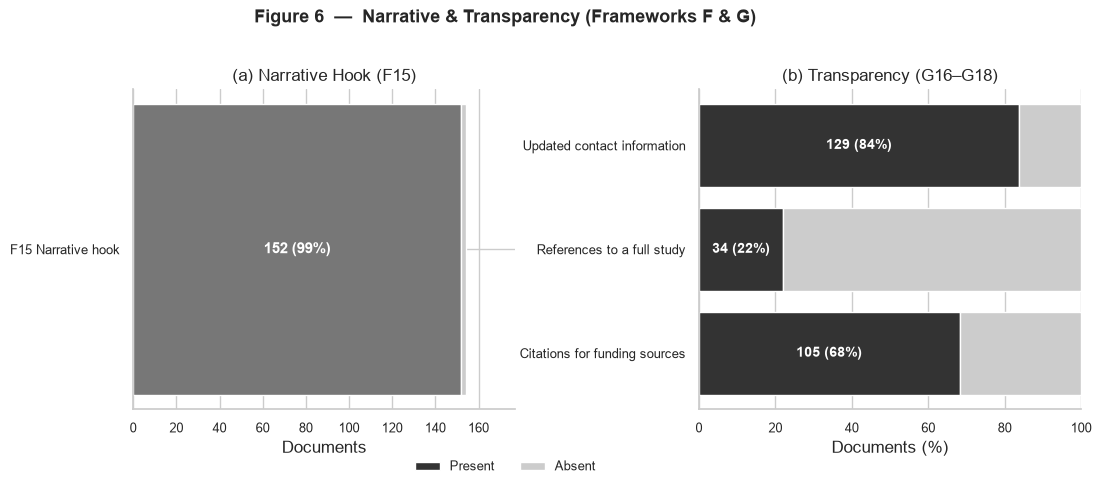

In [90]:
sns.set_context('notebook')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# (a) Narrative hook: present vs absent (horizontal stacked)
if 'F15_narrative_hook' in analysis_df.columns:
    hook_n  = int(analysis_df['F15_narrative_hook'].astype(bool).sum())
    hook_ab = len(analysis_df) - hook_n
    axes[0].barh(['F15 Narrative hook'], [hook_n],  color=C_SECONDARY, edgecolor='white', label='Present')
    axes[0].barh(['F15 Narrative hook'], [hook_ab], left=[hook_n], color='#cccccc', edgecolor='white', label='Absent')
    axes[0].text(hook_n / 2, 0, f'{hook_n} ({hook_n / len(analysis_df):.0%})',
                 ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    axes[0].set_xlim(0, len(analysis_df) * 1.15)
    axes[0].set_xlabel('Documents')
    axes[0].set_title('(a) Narrative Hook (F15)')
else:
    axes[0].set_visible(False)

# (b) Transparency: G16 funding + G17 linked study + G18 contact (horizontal stacked)
transp_items_g = [
    ('Citations for funding sources', 'G16_funding'),
    ('References to a full study', 'G17_linked_study'),
    ('Updated contact information', 'G18_contact_info'),
]
t_rows = []
for label, col in transp_items_g:
    if col not in analysis_df.columns:
        continue
    s = analysis_df[col]
    if not s.notna().any():
        continue
    n = int(s.fillna(False).astype(bool).sum())
    t_rows.append((label, n, len(analysis_df) - n))

if t_rows:
    t_labels = [r[0] for r in t_rows]
    t_present = np.array([r[1] for r in t_rows], dtype=float)
    t_absent = np.array([r[2] for r in t_rows], dtype=float)
    t_present_pct = (t_present / len(analysis_df)) * 100 if len(analysis_df) else np.zeros_like(t_present)
    t_absent_pct = (t_absent / len(analysis_df)) * 100 if len(analysis_df) else np.zeros_like(t_absent)
    axes[1].barh(t_labels, t_present_pct, color=C_PRIMARY, edgecolor='white', label='Present')
    axes[1].barh(t_labels, t_absent_pct, left=t_present_pct, color='#cccccc', edgecolor='white', label='Absent')
    for i, (p_n, p_pct) in enumerate(zip(t_present, t_present_pct)):
        axes[1].text(p_pct / 2, i, f'{int(p_n)} ({p_pct:.0f}%)',
                     ha='center', va='center', color='white', fontsize=10, fontweight='bold')
    axes[1].set_xlim(0, 100)
    axes[1].set_xlabel('Documents (%)')
    axes[1].set_title('(b) Transparency (G16–G18)')
else:
    axes[1].set_visible(False)

fig.suptitle('Figure 6  —  Narrative & Transparency (Frameworks F & G)', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='both', labelsize=9)
axes[1].tick_params(axis='both', labelsize=9)
legend_ax = axes[1] if t_rows else axes[0]
legend_handles, legend_labels = legend_ax.get_legend_handles_labels()
fig.legend(legend_handles, legend_labels, loc='lower center', ncol=2,
           bbox_to_anchor=(0.5, 0.03), frameon=False, fontsize=9)
fig.subplots_adjust(left=0.19, right=0.98, top=0.82, bottom=0.18, wspace=0.48)
save_standalone(fig, 'fig6_narrative_transparency')
plt.show()
sns.set_context('talk')

### I. Visual elements: charts, tables, figures, photos[](#7b.-Visual-Elements-(Framework-I))

The extraction pipeline checks for explicit in-text references to figures and tables (presence of visual elements) as part of front-matter extraction, and separately codes presence of charts, tables, figures, and photos. `data/Policy Briefs corpus.csv.xlsx` independently records human-coded presence of the same four visual-element types (columns "Chart", "Table", "Figure", "Photo"). Figure 6b compares the AI-detected and human-coded shares side by side for each element type.

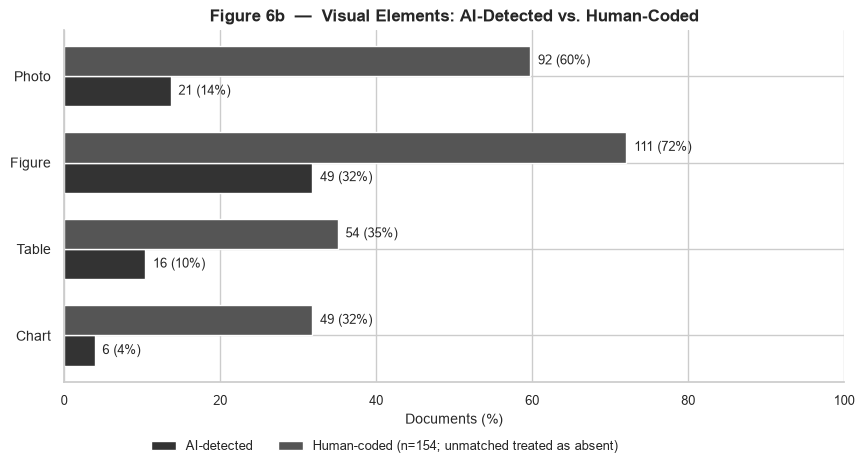

In [91]:
VISUAL_TYPES = ['chart', 'table', 'figure', 'photo']

ai_visual_cols = {v: f'I_has_{v}' for v in VISUAL_TYPES}
ai_available = {v: c for v, c in ai_visual_cols.items() if c in analysis_df.columns}

corpus_visual_cols = {'chart': 'Chart', 'table': 'Table', 'figure': 'Figure', 'photo': 'Photo'}

if len(corpus_sheet):
    human_visual = corpus_sheet.set_index('doc_id')[list(corpus_visual_cols.values())].map(_parse_yes_no_or_x)
else:
    human_visual = pd.DataFrame()

if ai_available or len(human_visual):
    sns.set_context('notebook')
    fig, ax = plt.subplots(figsize=(10, 5.5))
    y = np.arange(len(VISUAL_TYPES))
    h = 0.35

    if ai_available:
        ai_n = [
            int(analysis_df[ai_available[v]].fillna(False).astype(bool).sum()) if v in ai_available else np.nan
            for v in VISUAL_TYPES
        ]
        ai_pct = [
            float(analysis_df[ai_available[v]].fillna(False).astype(bool).mean()) * 100 if v in ai_available else np.nan
            for v in VISUAL_TYPES
        ]
    elif _has_col(documents, 'has_visual_elements'):
        # Fallback: only the combined boolean is available (pipeline not yet re-run with split fields)
        combined_pct = float(documents['has_visual_elements'].fillna(False).astype(bool).mean()) * 100
        ai_pct = [combined_pct] * len(VISUAL_TYPES)
        ai_n = [int(documents['has_visual_elements'].fillna(False).astype(bool).sum())] * len(VISUAL_TYPES)
        print('note: per-type AI detection (has_chart/has_table/has_figure/has_photo) not found in documents.csv; '
              'showing the combined has_visual_elements share for all four types until the pipeline is re-run.')
    else:
        ai_pct = [np.nan] * len(VISUAL_TYPES)
        ai_n = [np.nan] * len(VISUAL_TYPES)

    if len(human_visual):
        aligned_human = human_visual.reindex(analysis_df['doc_id']).fillna(False)
        denominator_n = len(analysis_df)
        human_n = [int(aligned_human[corpus_visual_cols[v]].astype(bool).sum()) for v in VISUAL_TYPES]
        human_pct = [float(aligned_human[corpus_visual_cols[v]].astype(bool).mean()) * 100 for v in VISUAL_TYPES]
    else:
        denominator_n = len(analysis_df)
        human_n = [np.nan] * len(VISUAL_TYPES)
        human_pct = [np.nan] * len(VISUAL_TYPES)

    ai_bars = ax.barh(y - h/2, ai_pct, height=h, color=C_PRIMARY, edgecolor='white', label='AI-detected')
    human_bars = ax.barh(y + h/2, human_pct, height=h, color=C_WARM, edgecolor='white',
                          label=f'Human-coded (n={denominator_n}; unmatched treated as absent)')
    for bar, n, v in zip(ai_bars, ai_n, ai_pct):
        if pd.notna(v):
            ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f'{int(n)} ({v:.0f}%)', va='center', fontsize=9)
    for bar, n, v in zip(human_bars, human_n, human_pct):
        if pd.notna(v):
            ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f'{int(n)} ({v:.0f}%)', va='center', fontsize=9)

    ax.set_yticks(y)
    ax.set_yticklabels([t.capitalize() for t in VISUAL_TYPES], fontsize=10)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Documents (%)', fontsize=10)
    ax.tick_params(axis='x', labelsize=9)
    ax.set_title('Figure 6b  —  Visual Elements: AI-Detected vs. Human-Coded', fontsize=12, fontweight='bold')
    legend_handles, legend_labels = ax.get_legend_handles_labels()
    fig.legend(legend_handles, legend_labels, loc='lower center', ncol=2,
               bbox_to_anchor=(0.5, 0.03), frameon=False, fontsize=9)
    fig.subplots_adjust(left=0.18, right=0.96, top=0.82, bottom=0.18)
    save_standalone(fig, 'fig6b_visual_elements')
    plt.show()
    sns.set_context('talk')
else:
    print('Visual-elements comparison skipped (neither AI nor human-coded columns available).')

### H. Policy-instrument categories[](#7.-Policy-Instrument-Categories-(Framework-H))

Dimensions H19–H23 classify each brief against six policy-instrument categories derived from the theoretical literature, plus an "Other" catch-all for instruments that do not fit the five substantive categories:

| # | Category | Description |
| --- | --- | --- |
| H19 | Command-and-Control | Regulatory mandates, standards, prohibitions |
| H20 | Economic Instruments | Taxes, subsidies, market mechanisms |
| H21 | Self-Regulation | Voluntary standards set by industry/profession |
| H22 | Voluntarism | Voluntary actions without binding standards |
| H23 | Information Strategies | Education, labelling, awareness campaigns |
| — | Other | A concrete instrument that does not fit the above categories |

A brief exhibiting two or more categories constitutes a **policy mix** (H24). Figure 7(a) compares AI-extracted and human-coded solutions. Each bar is the percentage of the full source sample (n=1,334 human-coded; n=2,673 LLM-identified) with that category present; source snippets are counted once per category, and unclassified snippets remain in the denominator. Because snippets can receive multiple category classifications, category shares may sum to more than 100%. Figure 7(b) shows document-level category co-occurrence from full-brief classification across the complete corpus. Figures 7(c-d) aggregate the AI-extracted and human-coded solution classifications to documents: a category is present in a document if any successfully classified solution contains it; off-diagonal cells count documents containing both categories, and diagonal cells count documents containing that category.

**Figure 7(c-d) — Document-level category co-occurrence from solution-level snippets.** Each matrix aggregates the six category decisions across all successfully classified solution passages within a document, separately for AI-extracted and human-coded snippets. An off-diagonal cell is the number of documents with both categories present; the diagonal is the number of documents with that category present. Documents with successfully classified passages but no identified category remain in the document-level denominator and contribute zeroes. Aggregated document counts and co-occurrence matrices are also saved as CSVs under `output/`.

![Figure 7(c-d): Document-level category co-occurrence aggregated from solution snippets](output/figures/fig7_solution_frame_document_cooccurrence.png)

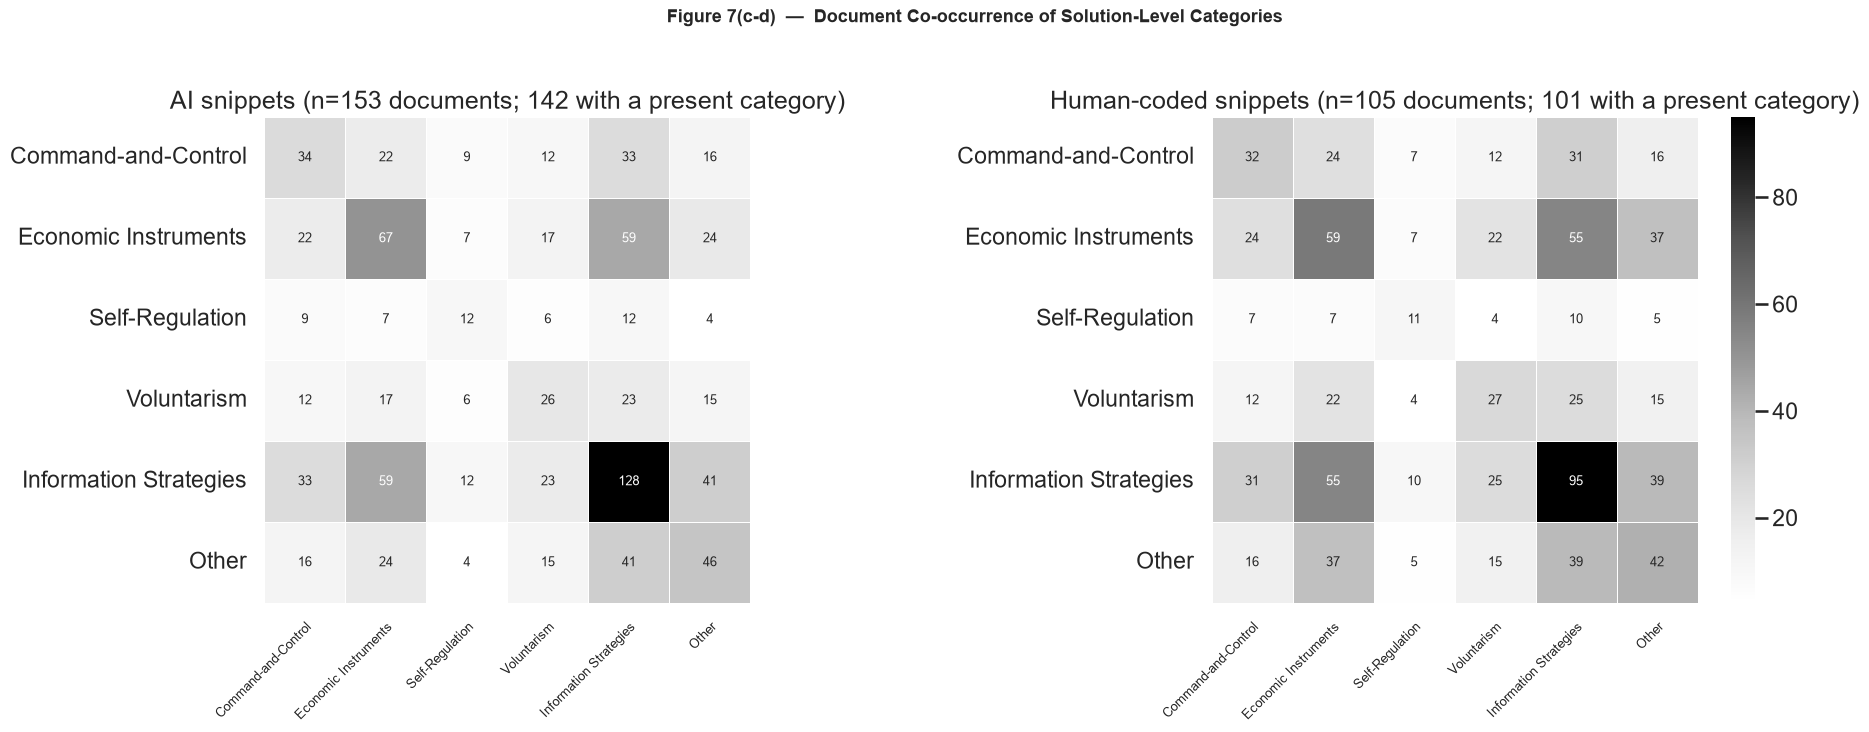

In [92]:
solution_category_order = [
    'Command-and-Control', 'Economic Instruments', 'Self-Regulation',
    'Voluntarism', 'Information Strategies', 'Other',
]
solution_category_ids = {
    'Command-and-Control': 'command_and_control',
    'Economic Instruments': 'economic_instruments',
    'Self-Regulation': 'self_regulation',
    'Voluntarism': 'voluntarism',
    'Information Strategies': 'information_strategies',
    'Other': 'other',
}
solution_category_sources = {
    'AI': OUTPUT_DIR / 'solution_frames_ai.csv',
    'Human-coded': OUTPUT_DIR / 'solution_frames_manual.csv',
}
solution_category_cooccurrence = {}
fig, axes = plt.subplots(1, 2, figsize=(19, 9))

for (source_label, source_path), ax in zip(solution_category_sources.items(), axes):
    if not source_path.exists():
        raise FileNotFoundError(f'Required solution classification output missing: {source_path}')
    source_results = pd.read_csv(source_path)
    classified = source_results[
        source_results['classification_status'].eq('classified')
    ]
    if classified.empty:
        raise ValueError(f'No classified solution categories in {source_path}')

    document_table = (
        classified.groupby('doc_id')['solution_key']
        .nunique()
        .rename('n_classified_solutions')
        .to_frame()
    )
    present = classified[classified['decision'].eq('present')]
    category_counts = present.groupby(['doc_id', 'frame_label'])['solution_key'].nunique()
    category_counts = category_counts.unstack(fill_value=0).reindex(
        columns=solution_category_order, fill_value=0
    )
    category_counts = category_counts.reindex(document_table.index, fill_value=0)
    document_presence = category_counts.gt(0).astype(int)
    cooccurrence = document_presence.T.dot(document_presence).reindex(
        index=solution_category_order, columns=solution_category_order, fill_value=0
    )
    solution_category_cooccurrence[source_label] = cooccurrence

    document_table['input_source'] = source_results['input_source'].iloc[0]
    document_table['source_provenance'] = source_results['source_provenance'].iloc[0]
    for category_label, category_id in solution_category_ids.items():
        document_table[f'{category_id}_solution_count'] = category_counts[category_label].astype(int)
        document_table[f'{category_id}_present'] = document_presence[category_label].astype(bool)
    document_table.to_csv(
        OUTPUT_DIR / f"solution_frames_document_{source_results['input_source'].iloc[0]}.csv",
        index_label='doc_id',
    )
    cooccurrence.to_csv(
        OUTPUT_DIR / f"solution_frame_document_cooccurrence_{source_results['input_source'].iloc[0]}.csv",
        index_label='category',
    )
    sns.heatmap(
        cooccurrence, annot=True, fmt='d', cmap=GREY_CMAP,
        linewidths=0.5, square=True, ax=ax, annot_kws={'size': 9},
        cbar=ax is axes[-1],
    )
    documents_with_category = int(document_presence.any(axis=1).sum())
    ax.set_title(
        f"{source_label} snippets (n={len(document_presence)} documents; "
        f'{documents_with_category} with a present category)'
    )
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels(
        ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=9
    )

fig.suptitle(
    'Figure 7(c-d)  —  Document Co-occurrence of Solution-Level Categories',
    fontsize=13, fontweight='bold',
)
fig.subplots_adjust(left=0.08, right=0.95, bottom=0.32, top=0.86, wspace=0.5)
save_standalone(fig, 'fig7_solution_frame_document_cooccurrence')
plt.show()

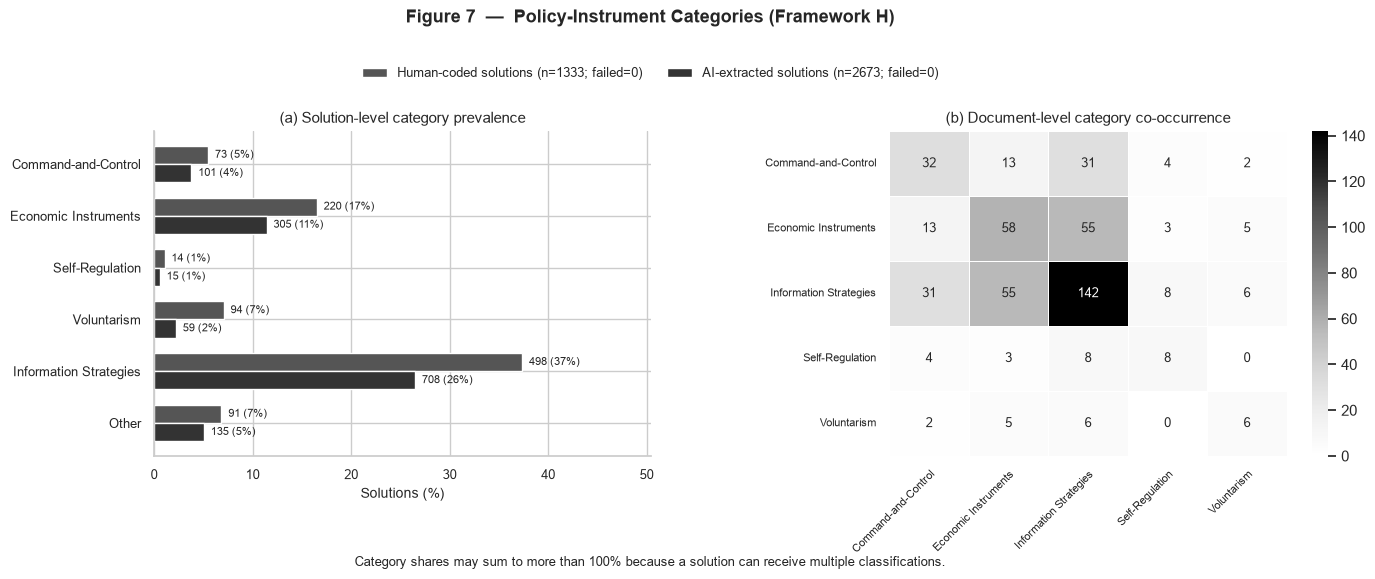

In [93]:
sns.set_context('notebook')
fig = plt.figure(figsize=(16, 5.8))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2)

solution_category_paths = {
    'Human-coded solutions': OUTPUT_DIR / 'solution_frames_manual.csv',
    'AI-extracted solutions': OUTPUT_DIR / 'solution_frames_ai.csv',
}
category_order = [
    'Command-and-Control', 'Economic Instruments', 'Self-Regulation',
    'Voluntarism', 'Information Strategies', 'Other',
]
category_rows = []
human_solution_sample_size = 1333
ai_solution_candidates = recommendations[
    recommendations['extraction_type'].astype(str).str.lower().isin(RECOMMENDATION_ANALYSIS_TYPES)
].copy()
ai_solution_text_col = (
    'source_text_raw' if 'source_text_raw' in ai_solution_candidates.columns
    else 'source_text'
)
if ai_solution_text_col in ai_solution_candidates.columns:
    ai_solution_candidates = ai_solution_candidates[
        ai_solution_candidates[ai_solution_text_col].notna()
        & ai_solution_candidates[ai_solution_text_col].astype(str).str.strip().ne('')
    ]
ai_solution_sample_size = (
    int(ai_solution_candidates['rec_id'].nunique())
    if 'rec_id' in ai_solution_candidates.columns
    else len(ai_solution_candidates)
)
for source_label, path in solution_category_paths.items():
    if not path.exists():
        continue
    source_results = pd.read_csv(path)
    classified = source_results[source_results['classification_status'].eq('classified')]
    required_category_ids = set(source_results['frame_id'].dropna().unique())
    category_ids_by_solution = classified.groupby('solution_key')['frame_id'].agg(set)
    complete_keys = category_ids_by_solution[
        category_ids_by_solution.map(lambda ids: ids == required_category_ids)
    ].index
    classified = classified[classified['solution_key'].isin(complete_keys)]
    failed_inputs = source_results.loc[
        source_results['classification_status'].eq('error'), ['doc_id', 'parent_id']
    ].drop_duplicates()
    failed_n = len(failed_inputs)
    present = classified[classified['decision'].eq('present')]
    present_inputs = present[['doc_id', 'parent_id', 'frame_label']].drop_duplicates()
    counts = present_inputs.groupby('frame_label').size()
    denominator = (
        human_solution_sample_size if source_label == 'Human-coded solutions'
        else ai_solution_sample_size
    )
    for category_label in category_order:
        category_rows.append({
            'source': source_label,
            'category': category_label,
            'count': int(counts.get(category_label, 0)),
            'denominator': denominator,
            'percent': float(counts.get(category_label, 0) / denominator * 100) if denominator else 0.0,
            'failed': failed_n,
        })

prevalence = pd.DataFrame(category_rows)
if not prevalence.empty:
    y = np.arange(len(category_order))
    h = 0.35
    available_sources = prevalence['source'].unique().tolist()
    ordered_sources = [
        ('Human-coded solutions', C_WARM),
        ('AI-extracted solutions', C_PRIMARY),
    ]
    ordered_sources = [(source, color) for source, color in ordered_sources if source in available_sources]
    offsets = np.linspace(-h / 2, h / 2, len(ordered_sources)) if len(ordered_sources) > 1 else [0]
    for offset, (source_label, color) in zip(offsets, ordered_sources):
        source_data = prevalence[prevalence['source'].eq(source_label)].set_index('category')
        vals = [float(source_data.loc[category, 'percent']) if category in source_data.index else 0.0 for category in category_order]
        counts = [int(source_data.loc[category, 'count']) if category in source_data.index else 0 for category in category_order]
        denominator = int(source_data['denominator'].iloc[0]) if len(source_data) else 0
        failed = int(source_data['failed'].iloc[0]) if len(source_data) else 0
        bars = ax1.barh(y + offset, vals, height=h, color=color, edgecolor='white',
                        label=f'{source_label} (n={denominator}; failed={failed})')
        for bar, count, percent in zip(bars, counts, vals):
            ax1.text(bar.get_width() + 0.7, bar.get_y() + bar.get_height() / 2,
                     f'{count} ({percent:.0f}%)', va='center', fontsize=8)
    ax1.set_yticks(y)
    ax1.set_yticklabels(category_order, fontsize=9)
    ax1.invert_yaxis()
    ax1.set_xlim(0, max(50, float(prevalence['percent'].max()) * 1.35))
    ax1.set_xlabel('Solutions (%)', fontsize=10)
    ax1.tick_params(axis='x', labelsize=9)
    ax1.set_title('(a) Solution-level category prevalence', fontsize=11)
    legend_handles, legend_labels = ax1.get_legend_handles_labels()
    fig.legend(legend_handles, legend_labels, loc='upper center', ncol=2,
               bbox_to_anchor=(0.5, 0.9), frameon=False, fontsize=9)
    fig.text(
        0.5, 0.015,
        'Category shares may sum to more than 100% because a solution can receive multiple classifications.',
        ha='center', va='bottom', fontsize=9,
    )
else:
    ax1.text(0.5, 0.5, 'Run solution classification for both sources first.',
             ha='center', va='center', transform=ax1.transAxes)
    ax1.set_axis_off()

if len(frames):
    _fp2 = frames[frames['decision'] == 'present']
    _pm = _fp2.assign(v=1).pivot_table(
        index='doc_id', columns='frame_label', values='v', fill_value=0
    )
    _cooc = _pm.T.dot(_pm)
    sns.heatmap(
        _cooc, annot=True, fmt='.0f', cmap=GREY_CMAP,
        linewidths=0.5, ax=ax2, annot_kws={'size': 9},
    )
    ax2.set_title('(b) Document-level category co-occurrence', fontsize=11)
    ax2.set_xlabel('')
    ax2.set_ylabel('')
    ax2.set_xticklabels(
        ax2.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=8
    )
    ax2.tick_params(axis='y', labelsize=8)

fig.suptitle('Figure 7  —  Policy-Instrument Categories (Framework H)', fontsize=13, fontweight='bold')
fig.subplots_adjust(left=0.19, right=0.96, top=0.77, bottom=0.21, wspace=0.48)
save_standalone(fig, 'fig7_policy_instrument_categories')
plt.show()

## 5. Solution pathways[](#8.-Solution-Pathways-(Sankey))

This section maps how recommendations flow from the **issuing institution** (by dominant affiliation type per document) through the **extraction type** (the semantic role of the recommendation — e.g. policy option, regulatory measure, actor responsibility) to the **target actor type** (who the recommendation is directed at).

Each link width is proportional to the number of recommendation records taking that path. The chart highlights which affiliation types tend to produce different recommendation styles and which actor types are most frequently targeted. This figure remains separate from the new source-aware manual-vs-AI downstream comparison used earlier in the section.

In [94]:
from IPython.display import Image, display

try:
    import plotly.graph_objects as go
    _plotly_ok = True
except ImportError:
    print("plotly not installed — run: pip install plotly>=5.0.0")
    _plotly_ok = False

if _plotly_ok and len(recommendation_content) and len(documents):
    from collections import Counter

    # ── dominant affiliation type per document ────────────────────────
    def _dominant_affil(s):
        if pd.isna(s) or str(s).strip() == '':
            return 'Other'
        parts = [t.strip() for t in str(s).split(';') if t.strip()]
        return Counter(parts).most_common(1)[0][0] if parts else 'Other'

    _doc_affil = (
        documents.set_index('doc_id')['fm_affiliation_types']
        .apply(_dominant_affil)
        if 'fm_affiliation_types' in documents.columns
        else pd.Series('Other', index=documents['doc_id'])
    )

    recs_s = recommendation_content.copy()
    recs_s['affiliation']   = recs_s['doc_id'].map(_doc_affil).fillna('Other')
    recs_s['ext_type']      = recs_s['extraction_type'].fillna('unknown')
    recs_s['actor']         = recs_s['actor_type'].fillna('Unspecified')

    # ── build node list: affiliation → ext_type → actor ──────────────
    affiliations = sorted(recs_s['affiliation'].unique())
    ext_types    = sorted(recs_s['ext_type'].unique())
    actors       = sorted(recs_s['actor'].unique())

    nodes      = affiliations + ext_types + actors
    node_idx   = {n: i for i, n in enumerate(nodes)}
    node_color = (
        ['#333333'] * len(affiliations) +
        ['#777777'] * len(ext_types) +
        ['#AAAAAA'] * len(actors)
    )

    src, tgt, val = [], [], []

    for (a, e), cnt in recs_s.groupby(['affiliation', 'ext_type']).size().items():
        src.append(node_idx[a]); tgt.append(node_idx[e]); val.append(int(cnt))

    for (e, ac), cnt in recs_s.groupby(['ext_type', 'actor']).size().items():
        src.append(node_idx[e]); tgt.append(node_idx[ac]); val.append(int(cnt))

    fig8 = go.Figure(go.Sankey(
        arrangement='snap',
        node=dict(
            label=nodes,
            color=node_color,
            pad=20,
            thickness=18,
            line=dict(color='white', width=0.5),
        ),
        link=dict(source=src, target=tgt, value=val, color='rgba(150,150,150,0.25)'),
    ))
    fig8.update_layout(
        title_text='Figure 8  —  Solution Pathways: Issuing Institution → Type → Target Actor',
        title_font_size=14,
        font_size=11,
        height=600,
    )
    fig8.show()

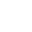

In [95]:
if len(report_recommendations):
    actor_df = report_recommendations.copy()
    actor_df['provenance_label'] = actor_df['provenance'].map({'manual_coded': 'Human-identified solution passages', 'ai_full_text': 'Full-brief LLM solution extraction'})

    actor_col = 'actor_type' if 'actor_type' in actor_df.columns else None
    if actor_col is None:
        actor_df['issuing_actor_group'] = 'Unspecified'
    else:
        actor_df['issuing_actor_group'] = actor_df[actor_col].fillna('unspecified').astype(str).str.lower()

    target_col = 'target_raw' if 'target_raw' in actor_df.columns else ('target_text_raw' if 'target_text_raw' in actor_df.columns else None)

    def _bucket_target(text):
        if pd.isna(text):
            return 'unspecified'
        t = str(text).lower().strip()
        if not t:
            return 'unspecified'
        if any(k in t for k in ['government', 'ministry', 'policy maker', 'policymaker', 'public authority', 'administration']):
            return 'government'
        if any(k in t for k in ['eu', 'european commission', 'european union']):
            return 'eu_institutions'
        if any(k in t for k in ['un ', 'united nations', 'fao', 'world bank', 'international']):
            return 'international_organizations'
        if any(k in t for k in ['company', 'industry', 'business', 'private sector', 'enterprise']):
            return 'private_sector'
        if any(k in t for k in ['ngo', 'civil society', 'community', 'citizen']):
            return 'civil_society'
        if any(k in t for k in ['research', 'university', 'academic', 'scientist']):
            return 'research_institutions'
        if any(k in t for k in ['farmer', 'household', 'individual', 'consumer']):
            return 'individuals'
        return 'other'

    if target_col is None:
        actor_df['target_actor_group'] = 'unspecified'
    else:
        actor_df['target_actor_group'] = actor_df[target_col].apply(_bucket_target)

    def _relative_stack(ax, value_col, title):
        counts = actor_df.groupby([value_col, 'provenance_label']).size().unstack(fill_value=0)
        counts = counts.sort_values(by=counts.columns.tolist(), ascending=False)
        if counts.empty:
            ax.set_visible(False)
            return

        shares = counts.div(counts.sum(axis=1), axis=0) * 100
        manual_vals = shares['Human-identified solution passages'] if 'Human-identified solution passages' in shares.columns else pd.Series(0, index=shares.index)
        ai_vals = shares['Full-brief LLM solution extraction'] if 'Full-brief LLM solution extraction' in shares.columns else pd.Series(0, index=shares.index)

        ax.barh(shares.index, manual_vals, color=C_WARM, edgecolor='white', label='Human-identified solution passages')
        ax.barh(shares.index, ai_vals, left=manual_vals, color=C_PRIMARY, edgecolor='white', label='Full-brief LLM solution extraction')
        ax.set_xlim(0, 100)
        ax.set_xlabel('Share within actor category (%)')
        ax.set_title(title)

    fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
    _relative_stack(axes[0], 'issuing_actor_group', 'Figure 4(b)  —  Issuing actor provenance mix')
    _relative_stack(axes[1], 'target_actor_group', 'Figure 4(b)  —  Target actor provenance mix')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles[::-1], labels[::-1], loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=1, frameon=False)
    plt.tight_layout(rect=(0, 0.2, 1, 1))
    save_standalone(fig, 'fig4b_actor_provenance_mix')
    plt.show()
else:
    print('Source-aware actor chart skipped because no downstream recommendation sources were available.')

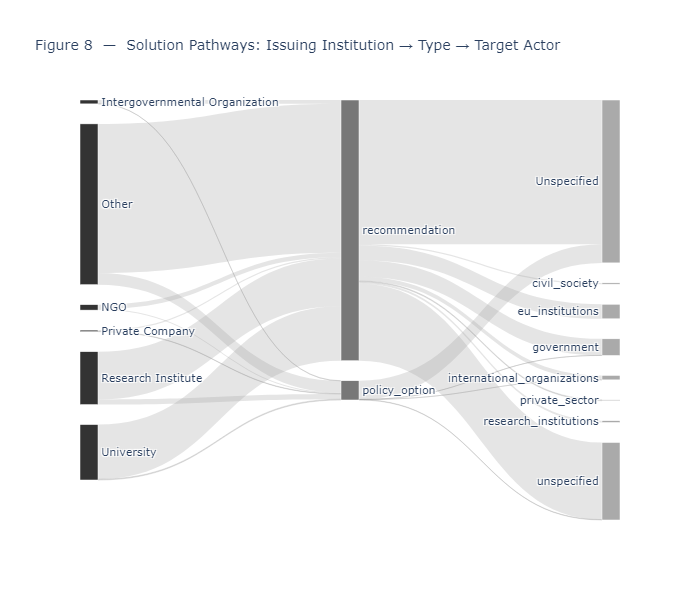

In [96]:
from IPython.display import Image
fig8.write_image(str(FIGURES_DIR / 'fig8_recommendation_pathways.png'))
fig8.write_image(str(FIGURES_DIR / 'fig8_recommendation_pathways.pdf'))
fig8.write_image("fig8.png")
Image("fig8.png")

### A. Document structure and corpus scope

Document length and corpus composition provide the baseline for interpreting all subsequent framework indicators.

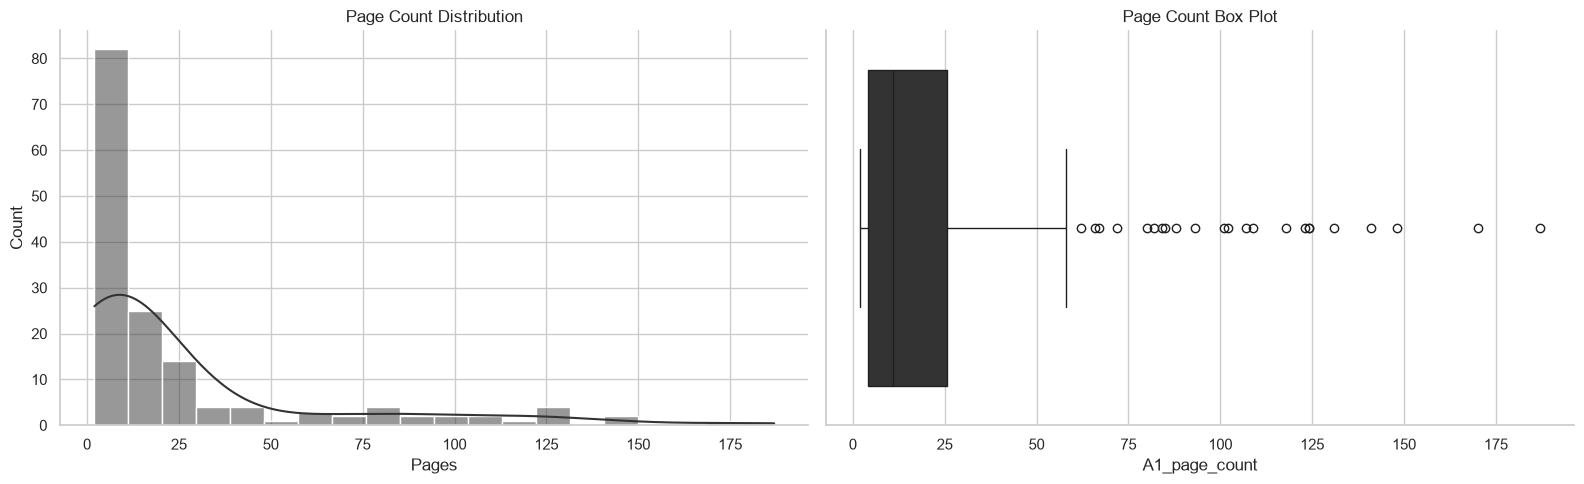

,count,mean,std,min,25%,50%,75%,max
Page Count,154.0,26.194805,37.785095,2.0,4.0,11.0,25.75,187.0


In [97]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(analysis_df['A1_page_count'], bins=20, kde=True, ax=axes[0], color=C_PRIMARY)
axes[0].set_title('Page Count Distribution')
axes[0].set_xlabel('Pages')

sns.boxplot(x=analysis_df['A1_page_count'], ax=axes[1], color=C_PRIMARY)
axes[1].set_title('Page Count Box Plot')
plt.tight_layout()
plt.show()
sns.set_context('talk')

display(analysis_df['A1_page_count'].describe().to_frame('Page Count').T)

## 4. Source comparison within framework results

The source-comparison outputs should be interpreted alongside the relevant framework indicators above. They compare what is detected when recommendation passages are selected by human coders versus identified from complete briefs by an LLM. Human-selected passages are subsequently processed by an LLM only to structure fields; they are therefore not purely manual classifications.

## 6. Appendix: quality assurance and technical diagnostics

This appendix retains the non-overlapping diagnostics from the exploratory report. Technical source labels and file-level provenance are kept here rather than in reader-facing figure titles and legends.

## QA Appendix: Raw Extraction Distributions & Correlations[](#QA-Appendix:-Raw-Extraction-Distributions-&-Correlations)

Low-level diagnostics on data quality, missingness, and inter-variable relationships.

,dataset,rows,columns,missing_cells
0,documents,154,39,896
1,frames,924,11,1272
2,recommendations,2826,20,27755
3,structural_core,154,13,3


**Top missing columns in documents.csv:**

,missing
warnings,154
fm_emails,124
linked_studies_raw,120
title,119
author,107
fm_urls,60
fm_affiliations,57
fm_affiliation_types,57
funding_statements_raw,49
fm_authors,49


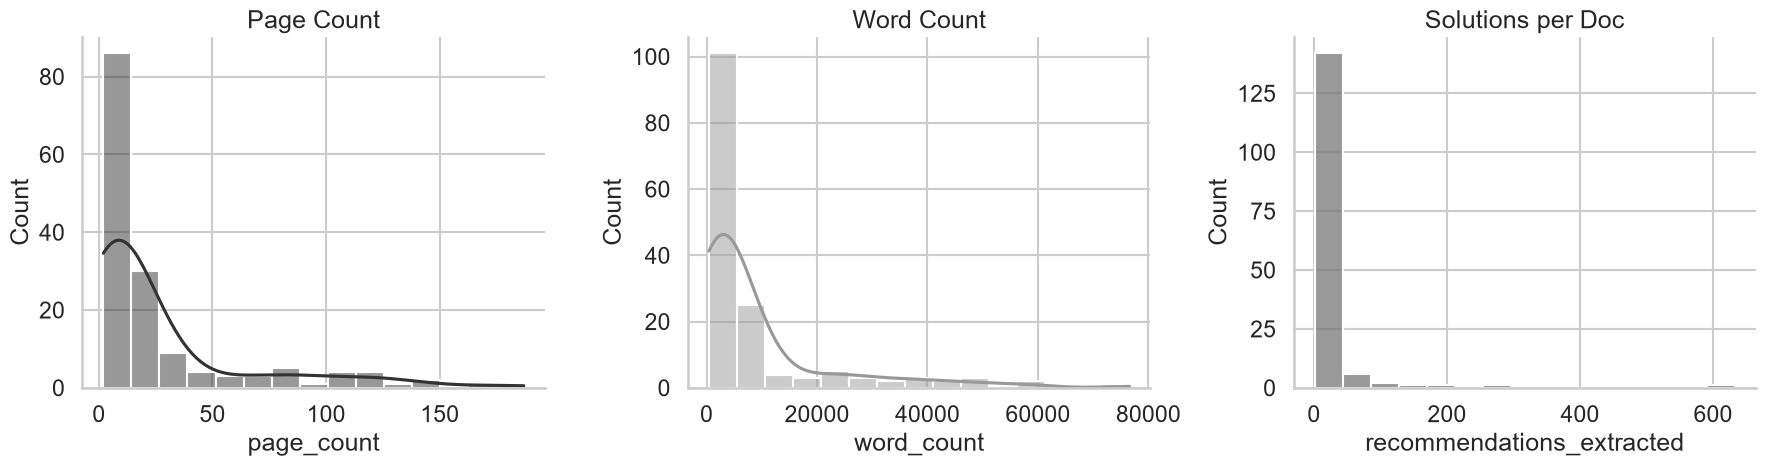

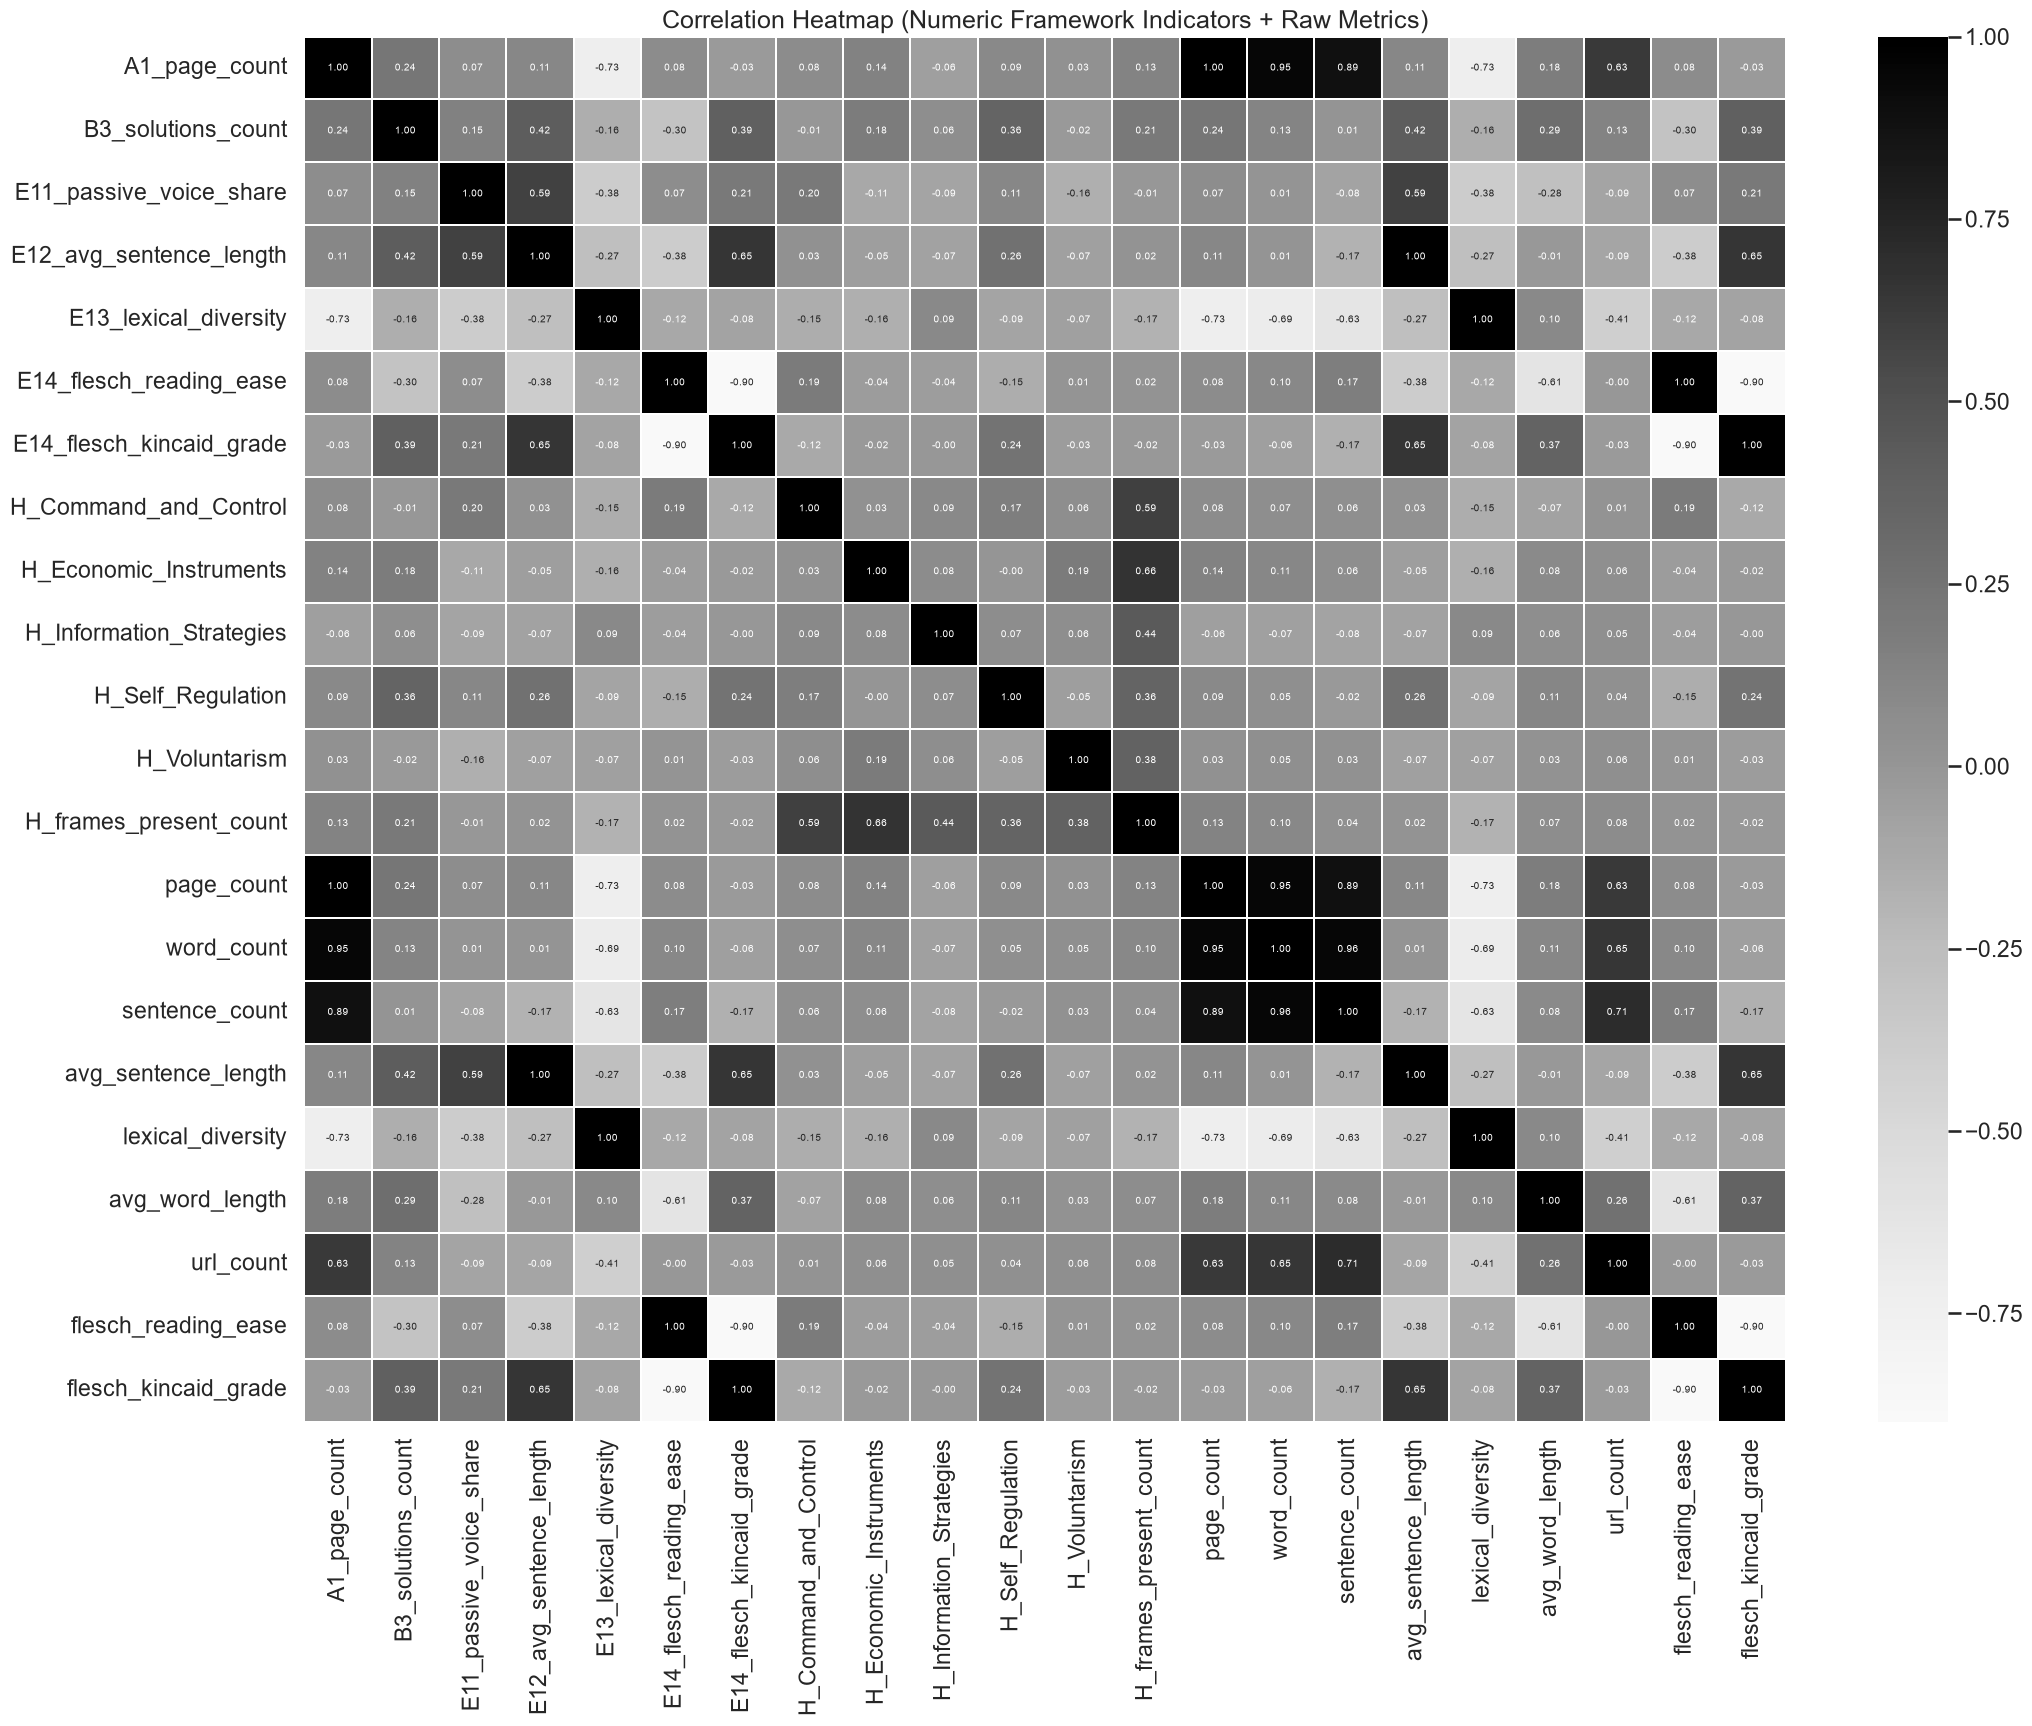

**Top 10 documents by recommendation count:**

,doc_id,page_count,word_count,recommendations_extracted
143,desira_1,170,76556,633
152,silvanus_1,148,58429,266
141,branches_1,131,48738,178
153,silvanus_2,118,57508,130
142,branches_2,67,25219,111
144,eklipse_4,107,50626,110
146,impetus,123,42513,84
147,innoforest,84,32817,71
145,eklipse_6,124,36860,70
150,phusicos_1,109,37121,65


In [98]:
# ── Dataset-level summary ────────────────────────────────────────────────
qa_summary = pd.DataFrame({
    'dataset': ['documents', 'frames', 'recommendations', 'structural_core'],
    'rows': [len(documents), len(frames), len(recommendations), len(structural_core)],
    'columns': [documents.shape[1], frames.shape[1], recommendations.shape[1], structural_core.shape[1]],
    'missing_cells': [
        documents.isna().sum().sum(), frames.isna().sum().sum(),
        recommendations.isna().sum().sum(), structural_core.isna().sum().sum()
    ],
})
display(qa_summary)

# ── Missingness in documents ────────────────────────────────────────────
display(Markdown('**Top missing columns in documents.csv:**'))
display(documents.isna().sum().sort_values(ascending=False).head(10).rename('missing').to_frame())

# ── Key distributions ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(documents['page_count'], bins=15, kde=True, ax=axes[0], color=C_PRIMARY)
axes[0].set_title('Page Count')
sns.histplot(documents['word_count'], bins=15, kde=True, ax=axes[1], color=C_ACCENT)
axes[1].set_title('Word Count')
if _has_col(documents, 'recommendations_extracted'):
    sns.histplot(documents['recommendations_extracted'], bins=15, ax=axes[2], color=C_SECONDARY)
    axes[2].set_title('Solutions per Doc')
plt.tight_layout()
save_standalone(fig, 'qa_key_distributions')
plt.show()

# ── Correlation heatmap ─────────────────────────────────────────────────
numeric_cols = [c for c in [
    'page_count', 'word_count', 'sentence_count', 'avg_sentence_length',
    'lexical_diversity', 'avg_word_length', 'url_count',
    'flesch_reading_ease', 'flesch_kincaid_grade',
] if c in documents.columns]
# Add framework derived numerics
for c in analysis_df.select_dtypes(include='number').columns:
    if c not in numeric_cols and c != 'doc_id':
        numeric_cols.append(c)

corr_df = analysis_df.merge(documents[['doc_id'] + [c for c in numeric_cols if c in documents.columns]],
                            on='doc_id', how='left', suffixes=('', '_dup'))
# Drop dups
corr_df = corr_df[[c for c in corr_df.columns if not c.endswith('_dup')]]
num = corr_df.select_dtypes(include='number').drop(columns=['doc_id'], errors='ignore')
if num.shape[1] > 2:
    corr = num.corr()
    fig, ax = plt.subplots(figsize=(max(12, num.shape[1]), max(10, num.shape[1] * 0.8)))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap=GREY_CMAP, center=0, linewidths=0.3, ax=ax,
                annot_kws={'size': 7})
    ax.set_title('Correlation Heatmap (Numeric Framework Indicators + Raw Metrics)')
    plt.tight_layout()
    save_standalone(fig, 'qa_correlation_heatmap')
    plt.show()

# ── Documents with extreme values ──────────────────────────────────────
display(Markdown('**Top 10 documents by recommendation count:**'))
display(
    documents[['doc_id', 'page_count', 'word_count', 'recommendations_extracted']]
    .sort_values('recommendations_extracted', ascending=False)
    .head(10)
)